# Лабораторная работа 4. Кластеризация

**Выполнил:** Моисеев Г. В., группа 4414

**Вариант 16.** В методических указаниях 5 вариантов, поэтому номер взят по кругу: 16 → 1, набор данных `medical_diagnosis.csv`.

**Цель работы:** изучение алгоритмов и методов кластеризации на практике.

Файл с данными читается из папки `data`, если ноутбук запущен локально. В Colab такой папки нет, и тогда файл скачивается из репозитория на GitHub.

`RANDOM_STATE` фиксирует начальные центры k-means, чтобы при каждом запуске получались одни и те же кластеры.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn import metrics
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler

%config InlineBackend.figure_format = 'retina'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
DATA_DIR = Path('data')
DATA_URL = 'https://raw.githubusercontent.com/Echways/ItDA/main/lab-4/data/'


def data_source(name):
    """Файл из папки data, а если её нет — тот же файл из репозитория на GitHub."""
    path = DATA_DIR / name
    return path if path.exists() else DATA_URL + name

## Часть 1. Кластеризация сгенерированных данных

### 1.1. Создание набора данных

Функция `make_data` взята из методических указаний без изменений. Она создаёт три группы точек с центрами (3, 3), (6, 9) и (9, 3), добавляет к каждой координате нормальный шум с единичным стандартным отклонением, а затем умножает `x` на 20 и `y` на 0.5. Центры групп после этого находятся в точках (60, 1.5), (120, 4.5) и (180, 1.5). В конце строки перемешиваются.

Значения параметров в методических указаниях не заданы. Взято `n = 100` объектов в каждой группе и `seed = 16` — номер варианта.

In [2]:
def make_data(n, seed):
    np.random.seed(seed)

    shift_matrix = np.array([[3, 3],
                             [6, 9],
                             [9, 3]])

    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])

    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]},
                      columns=['x', 'y'])
    df = df.sample(frac=1.0)

    return df


N_PER_GROUP = 100

points = make_data(n=N_PER_GROUP, seed=16)
print('Размер набора:', points.shape)
points.head()

Размер набора: (300, 2)


,x,y
222,165.181691,1.075852
81,57.902663,1.916698
151,122.602462,5.168187
251,174.284319,2.080600
227,123.626582,1.745424


In [3]:
points.describe().round(2)

,x,y
count,300.00,300.00
mean,118.71,2.51
std,51.28,1.47
min,10.27,0.51
25%,71.48,1.35
50%,117.25,1.82
75%,165.29,4.15
max,218.14,5.52


В наборе 300 объектов и два признака. `x` меняется от 10.27 до 218.14 при стандартном отклонении 51.28, `y` — от 0.51 до 5.52 при стандартном отклонении 1.47. Разброс `x` в 35 раз больше разброса `y`.

### 1.2. Стандартизация данных

k-means относит объект к ближайшему центру по евклидову расстоянию. Без стандартизации расстояние почти полностью определялось бы признаком `x`, и различие групп по `y` алгоритм бы не учитывал. `StandardScaler` приводит каждый признак к среднему 0 и стандартному отклонению 1.

In [4]:
points_scaler = StandardScaler().set_output(transform='pandas')
points_scaled = points_scaler.fit_transform(points)

# + 0 убирает отрицательный ноль после округления
pd.DataFrame({'Среднее до': points.mean(),
              'Ст. отклонение до': points.std(),
              'Среднее после': points_scaled.mean(),
              'Ст. отклонение после': points_scaled.std()}).round(2) + 0

,Среднее до,Ст. отклонение до,Среднее после,Ст. отклонение после
x,118.71,51.28,0.0,1.0
y,2.51,1.47,0.0,1.0


### 1.3. Кластеризация методом k-means для трёх кластеров

Метод `fit_predict` обучает модель и сразу возвращает метки кластеров. При `n_init=10` алгоритм запускается 10 раз с разными начальными центрами и оставляет разбиение с наименьшей суммой квадратов расстояний до центров.

In [5]:
kmeans_3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
labels_3 = kmeans_3.fit_predict(points_scaled)

print('Метки первых 20 объектов:', labels_3[:20])
print('Размеры кластеров:', np.bincount(labels_3))

Метки первых 20 объектов: [2 1 0 2 2 0 1 2 1 0 0 0 1 0 2 2 2 2 2 2]
Размеры кластеров: [100 100 100]


Каждый объект получил метку 0, 1 или 2. В каждом кластере ровно по 100 объектов — столько же, сколько в каждой сгенерированной группе. Сам номер кластера ничего не значит: важно только, что объекты с одинаковой меткой относятся к одному кластеру.

Центры кластеров (атрибут `cluster_centers_`) в стандартизованных координатах и в исходных единицах:

In [6]:
centers_3 = pd.DataFrame(kmeans_3.cluster_centers_, columns=['x', 'y'])
centers_3[['x в исходных единицах', 'y в исходных единицах']] = \
    points_scaler.inverse_transform(centers_3)
centers_3.rename_axis('Кластер').round(2)

,x,y,x в исходных единицах,y в исходных единицах
Кластер,,,,
0,-0.02,1.34,117.70,4.47
1,-1.14,-0.63,60.42,1.59
2,1.16,-0.71,178.02,1.46


В исходных единицах центры находятся в точках (117.70, 4.47), (60.42, 1.59) и (178.02, 1.46). Это близко к центрам, заложенным в `make_data`: (120, 4.5), (60, 1.5) и (180, 1.5).

### 1.4. Визуализация кластеров

Объекты каждого кластера показаны своим цветом, центры кластеров — чёрными крестами.

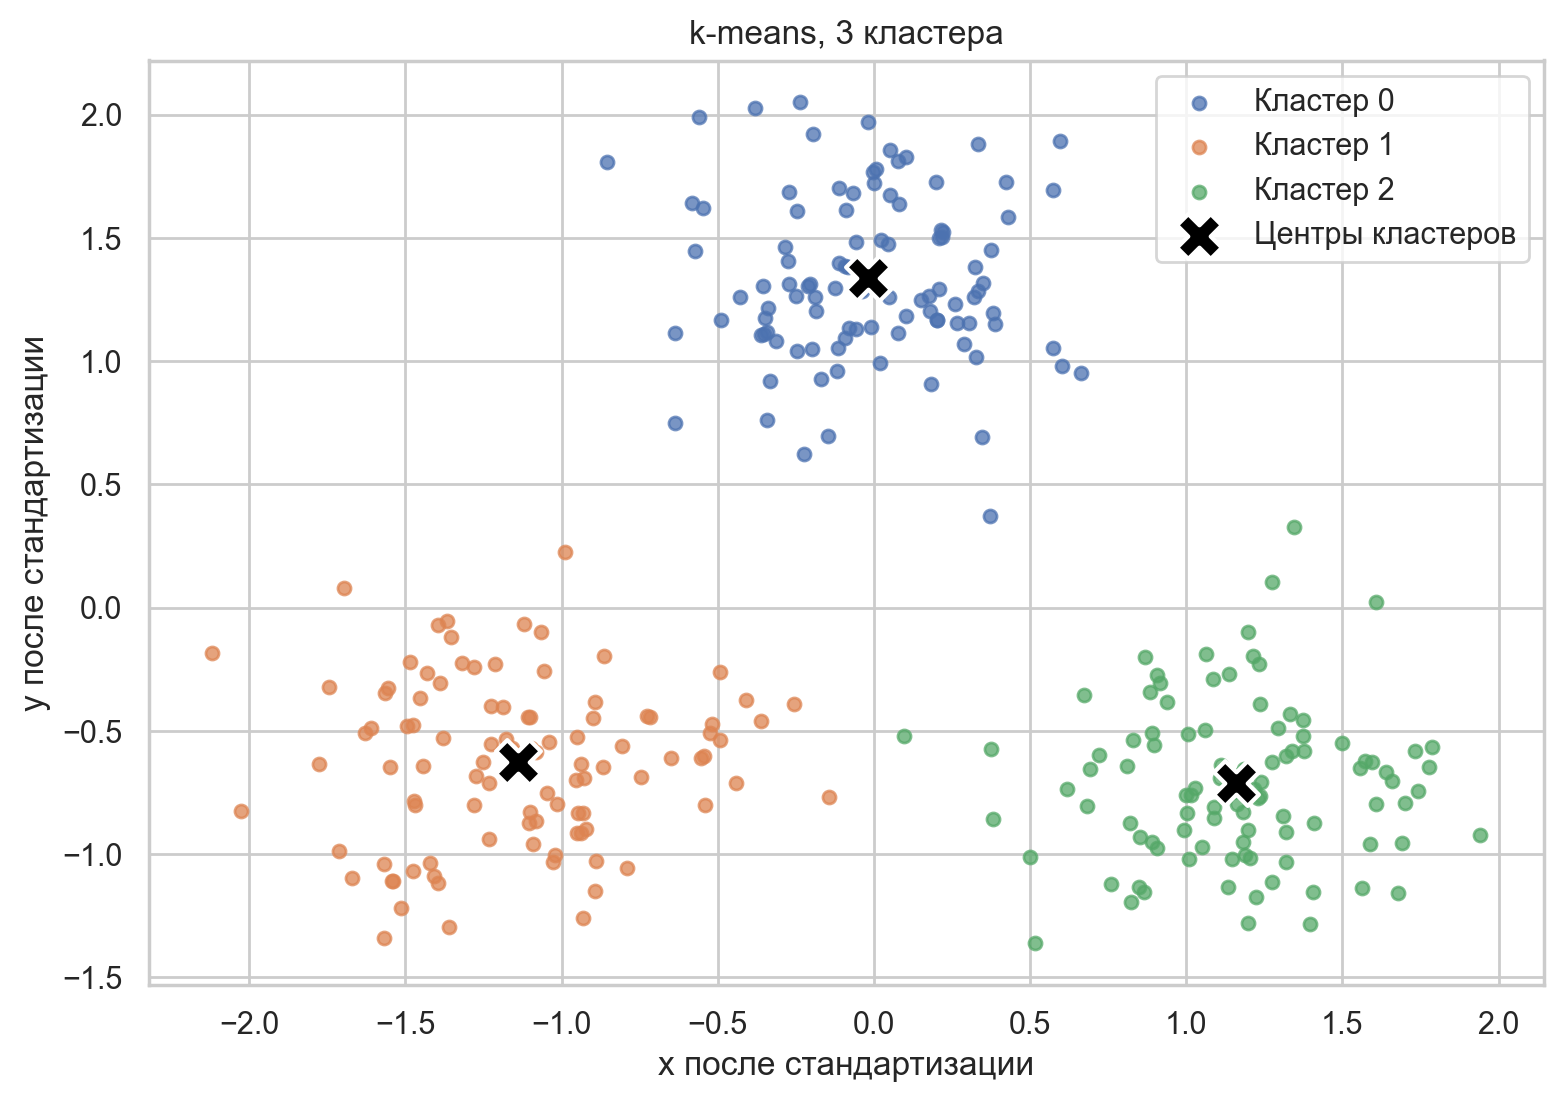

In [7]:
def plot_clusters(ax, data, model, title):
    """Объекты, окрашенные по кластерам, и центры кластеров."""
    for cluster in range(model.n_clusters):
        members = data[model.labels_ == cluster]
        ax.scatter(members['x'], members['y'], s=22, alpha=0.75, label=f'Кластер {cluster}')
    centers = model.cluster_centers_
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=260, color='black',
               edgecolor='white', linewidth=1.5, label='Центры кластеров')
    ax.set(xlabel='x после стандартизации', ylabel='y после стандартизации', title=title)
    ax.legend()


fig, ax = plt.subplots(figsize=(9, 6))
plot_clusters(ax, points_scaled, kmeans_3, 'k-means, 3 кластера')
plt.show()

Три облака точек отделены друг от друга, и каждое целиком окрашено одним цветом. Центры кластеров стоят в середине своих облаков.

### 1.5. Коэффициент силуэта

Коэффициент силуэта объекта сравнивает `a` — среднее расстояние до объектов своего кластера — и `b` — среднее расстояние до объектов ближайшего чужого кластера: `s = (b − a) / max(a, b)`. Значение близко к 1, когда объект лежит глубоко в своём кластере, около 0 — когда он на границе двух кластеров, меньше 0 — когда чужой кластер ближе своего. Функция `silhouette_score` возвращает среднее по всем объектам.

In [8]:
silhouette_3 = metrics.silhouette_score(points_scaled, labels_3)
print(f'Коэффициент силуэта для 3 кластеров: {silhouette_3:.3f}')

Коэффициент силуэта для 3 кластеров: 0.720


Коэффициент силуэта равен 0.720: кластеры плотные и хорошо отделены друг от друга.

### 1.6. Два и четыре кластера

Те же шаги повторены для `n_clusters = 2` и `n_clusters = 4`. Модель для трёх кластеров уже обучена и добавлена для сравнения.

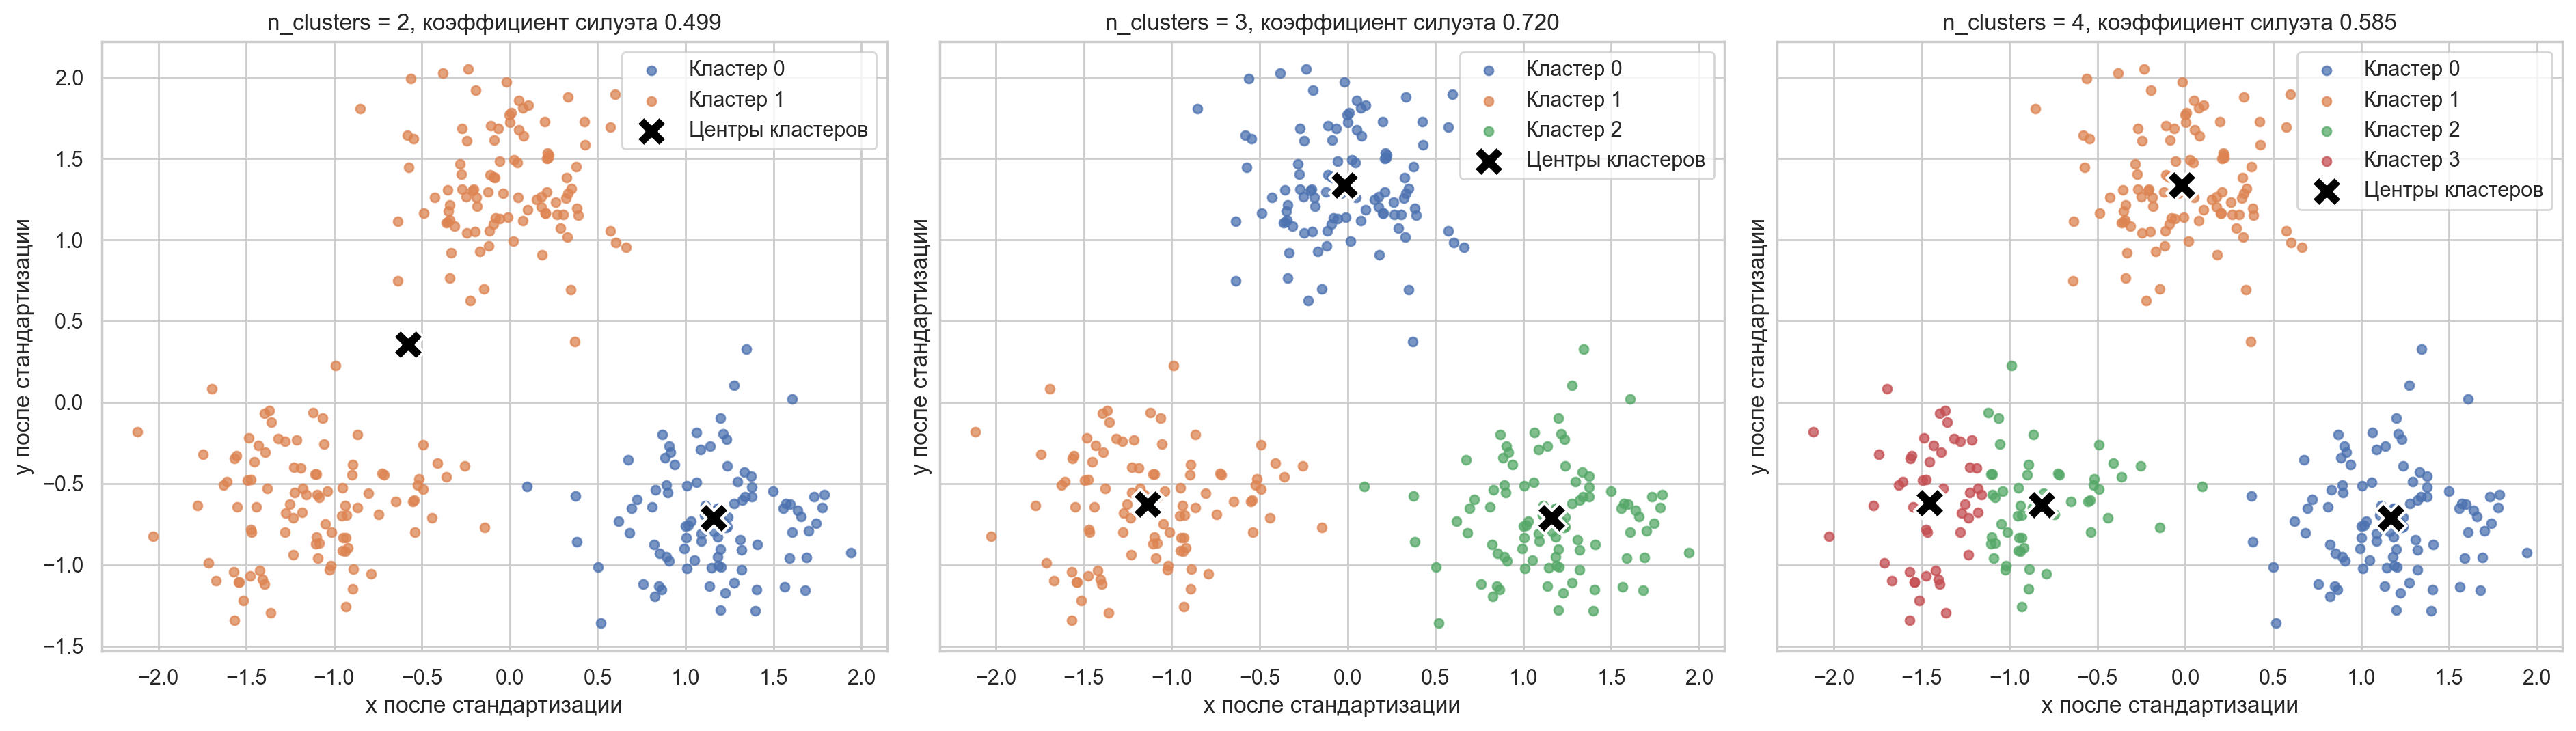

In [9]:
point_models = {3: kmeans_3}
for k in [2, 4]:
    point_models[k] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    point_models[k].fit(points_scaled)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)

for ax, k in zip(axes, [2, 3, 4]):
    silhouette = metrics.silhouette_score(points_scaled, point_models[k].labels_)
    plot_clusters(ax, points_scaled, point_models[k],
                  f'n_clusters = {k}, коэффициент силуэта {silhouette:.3f}')

fig.tight_layout()
plt.show()

Функция `make_data` перемешивает строки, но сохраняет исходный индекс: строки 0–99 — первая группа, 100–199 — вторая, 200–299 — третья. Поэтому номер сгенерированной группы равен целой части от деления индекса на 100, и с ним можно сравнить кластеры. Для сравнения взята метрика ARI: она равна 1, когда два разбиения совпадают, и близка к 0, когда совпадение случайное.

In [10]:
generated_groups = points.index // N_PER_GROUP

pd.DataFrame(
    {k: {'Коэффициент силуэта': round(metrics.silhouette_score(points_scaled, model.labels_), 3),
         'Инерция': round(model.inertia_, 1),
         'Размеры кластеров': np.bincount(model.labels_).tolist(),
         'ARI с исходными группами': round(metrics.adjusted_rand_score(generated_groups,
                                                                       model.labels_), 3)}
     for k, model in sorted(point_models.items())}
).T.rename_axis('n_clusters')

,Коэффициент силуэта,Инерция,Размеры кластеров,ARI с исходными группами
n_clusters,,,,
2,0.499,323.0,"[100, 200]",0.57
3,0.72,67.8,"[100, 100, 100]",1.0
4,0.585,57.9,"[99, 100, 52, 49]",0.861


In [11]:
pd.concat({f'n_clusters = {k}': pd.crosstab(generated_groups, model.labels_)
           for k, model in sorted(point_models.items())},
          axis=1).rename_axis('Исходная группа').rename_axis(['', 'Кластер'], axis=1)

n_clusters = 2      n_clusters = 3           n_clusters = 4  \
Кластер                      0    1              0    1    2              0   
Исходная группа                                                               
0                            0  100              0  100    0              0   
1                            0  100            100    0    0              0   
2                          100    0              0    0  100             99   

                              
Кластер            1   2   3  
Исходная группа               
0                  0  51  49  
1                100   0   0  
2                  0   1   0

- **2 кластера.** Коэффициент силуэта 0.499. Исходные группы 0 и 1 объединены в один кластер из 200 объектов, его центр оказался в пустом месте между двумя облаками. ARI = 0.570.
- **3 кластера.** Коэффициент силуэта наибольший, 0.720. Каждый кластер — ровно одна исходная группа, ARI = 1.
- **4 кластера.** Коэффициент силуэта 0.585. Исходная группа 0 разрезана пополам, на кластеры из 52 и 49 объектов, хотя на графике это одно облако. Сумма квадратов расстояний при этом уменьшилась мало: с 67.8 до 57.9. ARI = 0.861.

Оптимальное число кластеров — 3: при нём коэффициент силуэта максимален, а кластеры совпадают со сгенерированными группами.

### 1.7. Метод локтя

Для каждого `k` от 1 до 9 считается `J(C_k)` — сумма квадратов расстояний от объектов до центров их кластеров (атрибут `inertia_`). С ростом `k` она всегда убывает, поэтому ищут не минимум, а «локоть» — точку, после которой убывание резко замедляется.

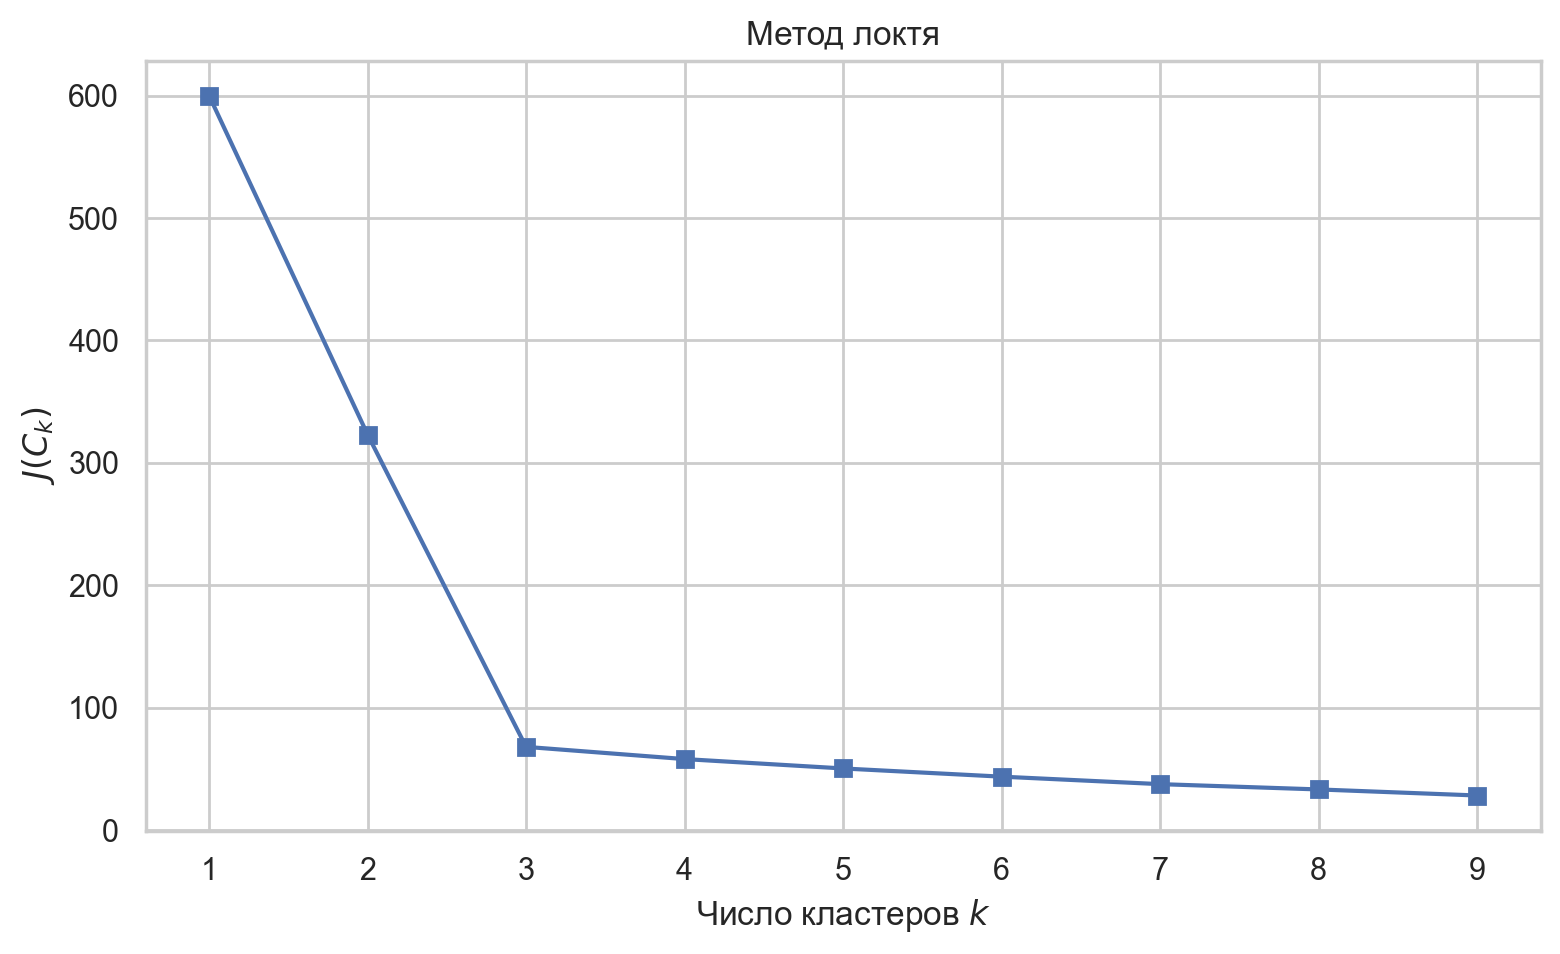

In [12]:
elbow_k = range(1, 10)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(points_scaled).inertia_
           for k in elbow_k]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(elbow_k, inertia, marker='s')
ax.set(xlabel='Число кластеров $k$', ylabel='$J(C_k)$', title='Метод локтя')
plt.show()

In [13]:
elbow = pd.DataFrame({'J(C_k)': inertia}, index=pd.Index(elbow_k, name='k'))
elbow['Снижение, %'] = -100 * elbow['J(C_k)'].pct_change()
elbow.round(1).T

k,1,2,3,4,5,6,7,8,9
J(C_k),600.0,323.0,67.8,57.9,50.2,43.5,37.4,33.1,28.1
"Снижение, %",NaN,46.2,79.0,14.7,13.3,13.3,14.1,11.6,15.0


При переходе от одного кластера к двум `J` уменьшается на 46.2 %, от двух к трём — ещё на 79.0 %. Дальше каждый новый кластер снижает её только на 12–15 %. Локоть находится в точке `k = 3`.

### 1.8. Выводы по части 1

- Сгенерированы 300 объектов трёх групп. Разброс `x` в 35 раз больше разброса `y`, поэтому перед кластеризацией признаки стандартизованы.
- k-means для трёх кластеров точно восстановил сгенерированные группы: по 100 объектов в кластере, ARI = 1, центры кластеров в исходных единицах близки к заложенным в функции.
- Коэффициент силуэта максимален при трёх кластерах: 0.720 против 0.499 для двух и 0.585 для четырёх. При двух кластерах алгоритм объединяет две группы, при четырёх — делит одну группу пополам.
- Метод локтя даёт то же число: после `k = 3` сумма квадратов расстояний почти перестаёт убывать.

## Часть 2. Кластеризация набора данных о пациентах

### 2.1. Загрузка данных

Набор данных `medical_diagnosis.csv` содержит информацию о болезнях. Каждая строка — один пациент.

| Столбец | Что хранит |
|---|---|
| `age` | возраст пациента, лет |
| `sex` | пол: `Male`, `Female` |
| `BMI` | индекс массы тела, кг/м² |
| `systolic_bp` | систолическое артериальное давление, мм рт. ст. |
| `cholesterol_mg_dl` | общий холестерин сыворотки, мг/дл |
| `fasting_glucose_mg_dl` | глюкоза крови натощак, мг/дл |
| `smoking_status` | статус курения: `Never`, `Former`, `Current` |
| `family_history` | наследственность по заболеванию: `Yes`, `No` |
| `activity_level` | уровень физической активности: `Low`, `Moderate`, `High` |
| `symptom_score` | суммарная выраженность симптомов, от 0 до 10 |
| `CRP_mg_L` | C-реактивный белок, мг/л — маркер воспаления |
| `WBC_10e9_L` | лейкоциты, ×10⁹/л |
| `ECG_result` | результат ЭКГ: `Normal`, `ST-T abnormality`, `LVH` |
| `Disease` | целевой класс: 1 — болеет, 0 — не болеет |

In [14]:
medical = pd.read_csv(data_source('medical_diagnosis.csv'))
medical.head()

,age,sex,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,CRP_mg_L,WBC_10e9_L,ECG_result,Disease
0,34,Male,16.8,132.0,196.0,78.0,Current,No,High,0.2,0.58,8.60,Normal,0
1,24,Female,29.2,118.0,182.0,96.0,Current,No,Moderate,3.2,2.72,6.54,Normal,0
2,19,Female,16.5,121.0,268.0,101.0,Current,No,Moderate,3.8,0.18,6.61,Normal,0
3,89,Female,15.4,117.0,136.0,96.0,Never,No,Low,2.6,1.83,5.67,Normal,0
4,66,Male,16.7,82.0,241.0,126.0,Former,No,Moderate,3.5,1.16,2.66,Normal,0


In [15]:
medical.info()
print('Дубликатов:', medical.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   object 
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   object 
 7   family_history         3031 non-null   object 
 8   activity_level         3031 non-null   object 
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   object 
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(2), object(5)
memory usage: 331.6+ 

В таблице 3031 строка и 14 столбцов, пропусков нет. Числовых столбцов 9, включая целевой `Disease`, категориальных 5. Типы столбцов соответствуют их содержанию. Одна строка полностью повторяет другую.

### 2.2. Предварительная обработка данных

Описательные статистики числовых столбцов:

In [16]:
medical.describe().round(2)

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3031.00,3031.00,3031.00,3031.00,3031.00,3031.00,3031.00,3031.00,3031.00
mean,53.18,26.47,122.42,202.74,94.37,2.04,1.38,6.83,0.02
std,20.74,5.87,17.86,53.74,19.55,1.36,3.16,1.98,0.13
min,18.00,13.50,82.00,85.00,56.00,0.00,0.10,2.30,0.00
25%,35.00,22.50,110.00,171.00,80.50,1.00,0.10,5.48,0.00
50%,53.00,26.30,122.00,200.00,94.00,2.00,0.52,6.75,0.00
75%,71.00,30.40,134.00,232.00,107.00,3.00,1.46,8.15,0.00
max,89.00,50.90,184.00,658.20,163.00,6.80,43.45,13.72,1.00


- У `cholesterol_mg_dl` максимум 658.2 почти втрое больше третьего квартиля (232).
- У `CRP_mg_L` максимум 43.45 при медиане 0.52 и третьем квартиле 1.46, стандартное отклонение (3.16) больше среднего (1.38). Распределение сильно скошено вправо.
- У остальных признаков среднее близко к медиане, а минимум и максимум правдоподобны: возраст от 18 до 89 лет, давление от 82 до 184.
- Среднее `Disease` равно 0.02: больных около 2 %.

Значения категориальных столбцов:

In [17]:
CATEGORICAL = ['sex', 'smoking_status', 'family_history', 'activity_level', 'ECG_result']

pd.Series({column: ', '.join(f'{value} — {count}'
                             for value, count in medical[column].value_counts().items())
           for column in CATEGORICAL}, name='Значения и число строк').to_frame()

,Значения и число строк
sex,"Male — 1526, Female — 1505"
smoking_status,"Never — 1540, Former — 923, Current — 568"
family_history,"No — 2010, Yes — 1021"
activity_level,"Moderate — 1370, Low — 1050, High — 611"
ECG_result,"Normal — 2382, ST-T abnormality — 531, LVH — 118"


В каждом столбце только те значения, что указаны в описании набора: опечаток и лишних категорий нет. В кластеризации категориальные признаки не участвуют: k-means и метод Уорда считают евклидово расстояние, а оно определено для числовых признаков.

**Аномальные строки.** Подозрительно большие максимумы у двух столбцов — холестерина и C-реактивного белка. Диаграмма рассеяния этих признаков:

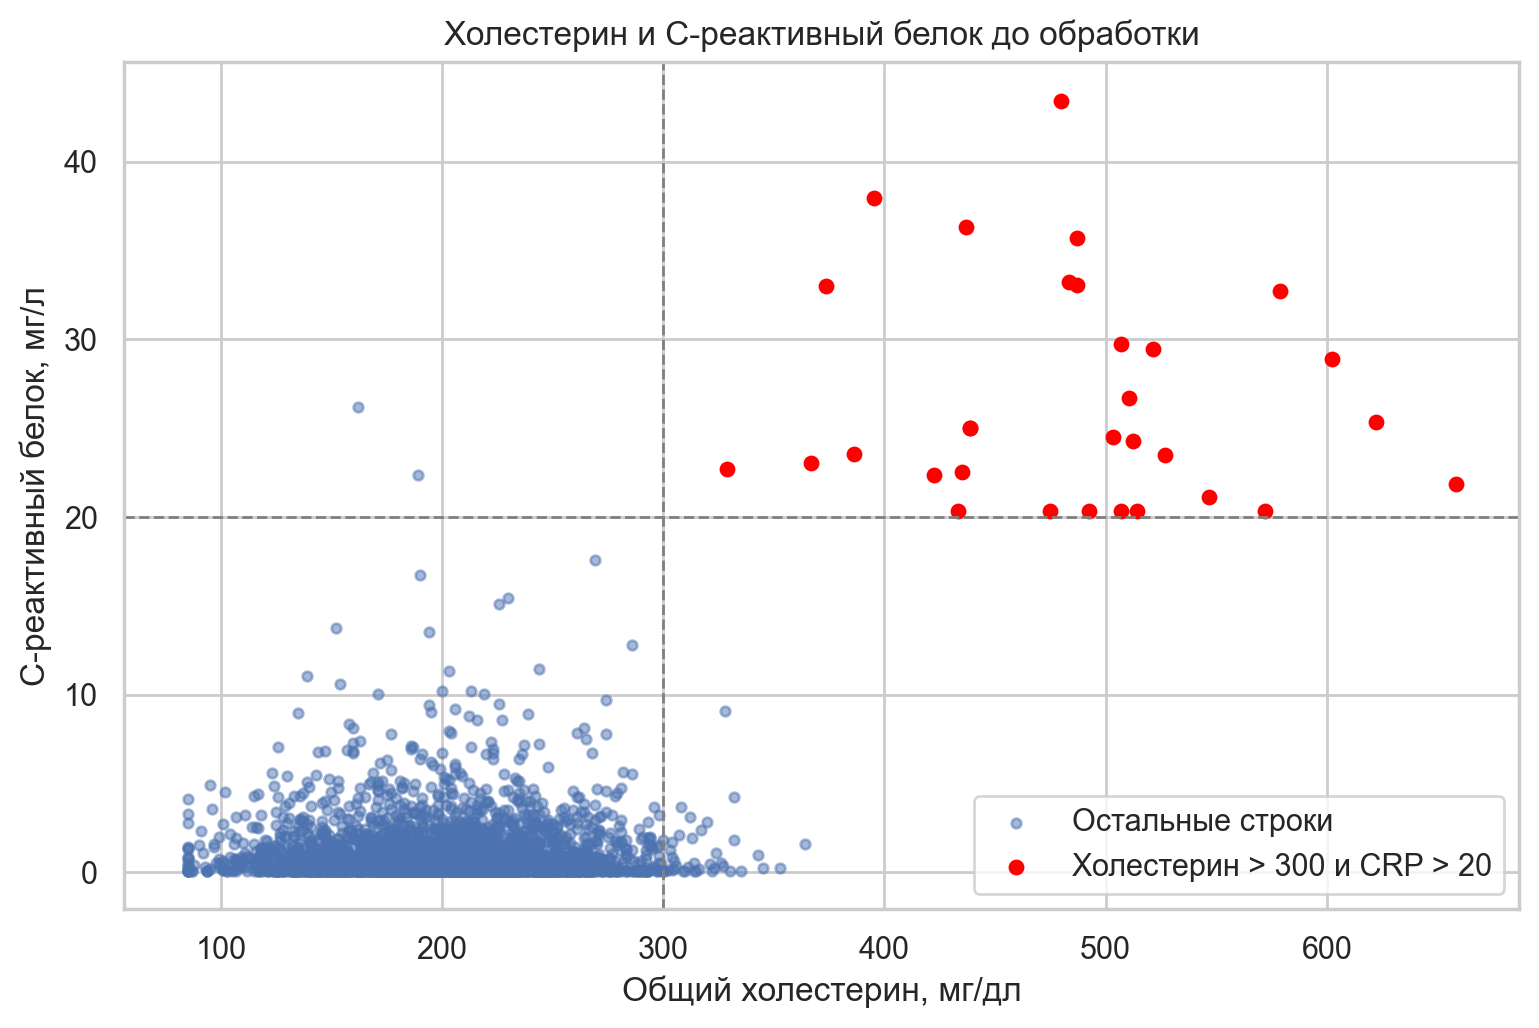

In [18]:
CHOLESTEROL_LIMIT, CRP_LIMIT = 300, 20
anomalous = (medical['cholesterol_mg_dl'] > CHOLESTEROL_LIMIT) & (medical['CRP_mg_L'] > CRP_LIMIT)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(medical.loc[~anomalous, 'cholesterol_mg_dl'], medical.loc[~anomalous, 'CRP_mg_L'],
           s=12, alpha=0.5, label='Остальные строки')
ax.scatter(medical.loc[anomalous, 'cholesterol_mg_dl'], medical.loc[anomalous, 'CRP_mg_L'],
           s=22, color='red', label='Холестерин > 300 и CRP > 20')
ax.axvline(CHOLESTEROL_LIMIT, color='gray', linestyle='--', linewidth=1)
ax.axhline(CRP_LIMIT, color='gray', linestyle='--', linewidth=1)
ax.set(xlabel='Общий холестерин, мг/дл', ylabel='C-реактивный белок, мг/л',
       title='Холестерин и C-реактивный белок до обработки')
ax.legend()
plt.show()

Основная масса пациентов лежит в левом нижнем углу. Справа вверху, отдельно от неё, расположена группа точек, у которых одновременно холестерин больше 300 и CRP больше 20. Проверяю эту группу:

In [19]:
fractional = medical['cholesterol_mg_dl'] % 1 != 0
anomalous_rows = medical.index[anomalous]

print('Строк в отдельной группе:', anomalous.sum())
print('Их номера: от', anomalous_rows.min(), 'до', anomalous_rows.max())
print('Дробный холестерин в этой группе:', fractional[anomalous].sum())
print('Дробный холестерин в остальных строках:', fractional[~anomalous].sum())
print('Строки-дубликаты:', medical.index[medical.duplicated(keep=False)].tolist())

NUMERIC = ['age', 'BMI', 'systolic_bp', 'cholesterol_mg_dl', 'fasting_glucose_mg_dl',
           'symptom_score', 'CRP_mg_L', 'WBC_10e9_L']

others = medical.loc[~anomalous, NUMERIC]
pd.DataFrame({'Медиана в группе': medical.loc[anomalous, NUMERIC].median(),
              'Медиана в остальных строках': others.median(),
              'Максимум в остальных строках': others.max()}).round(2)

Строк в отдельной группе: 31
Их номера: от 3000 до 3030
Дробный холестерин в этой группе: 26
Дробный холестерин в остальных строках: 0
Строки-дубликаты: [3008, 3024]


,Медиана в группе,Медиана в остальных строках,Максимум в остальных строках
age,65.00,53.00,89.00
BMI,24.80,26.40,50.90
systolic_bp,120.00,122.00,184.00
cholesterol_mg_dl,487.20,199.00,364.00
fasting_glucose_mg_dl,91.00,94.00,163.00
symptom_score,2.00,2.00,6.80
CRP_mg_L,24.48,0.51,26.20
WBC_10e9_L,6.86,6.74,13.72


- В группе 31 строка, и все они записаны подряд в самом конце файла: номера с 3000 по 3030.
- У 26 из них холестерин дробный, а во всех остальных 3000 строках он целый.
- Медиана холестерина в группе 487.2 — больше, чем максимум среди остальных строк (364). Медиана CRP 24.48 против 0.51.
- Остальные шесть признаков у этих строк лежат в тех же пределах, что и у остальных пациентов.
- Обе повторяющиеся строки (3008 и 3024) тоже из этой группы.

Положение в файле, другой формат значений и одновременное завышение двух признаков говорят о том, что это искажённые записи, а не пациенты с редкими анализами.

Для кластеризации они вредны по двум причинам. Центр кластера — это среднее, и далёкие точки сдвигают его к себе. Кроме того, они увеличивают стандартное отклонение признака, и после стандартизации различия между обычными пациентами по этому признаку сжимаются. Проверка — k-means для трёх кластеров на данных вместе с этими строками:

In [20]:
with_anomalies = StandardScaler().fit_transform(medical[NUMERIC])
check_model = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
check_labels = check_model.fit_predict(with_anomalies)

row_kind = anomalous.map({False: 'Обычная строка', True: 'Аномальная строка'})
pd.crosstab(pd.Series(check_labels, name='Кластер'), row_kind.rename(''))

,Аномальная строка,Обычная строка
Кластер,,
0,0,1538
1,0,1459
2,31,3


Алгоритм потратил отдельный кластер на 31 аномальную строку и ещё три строки с самым высоким CRP, а остальных 2997 пациентов просто разделил пополам. Аномальные строки удаляю.

In [21]:
medical = medical[~anomalous].reset_index(drop=True)

print('Строк после обработки:', len(medical))
print('Дубликатов:', medical.duplicated().sum())

Строк после обработки: 3000
Дубликатов: 0


Осталось 3000 строк. Дубликат исчез вместе с аномальными строками.

**Выбросы.** Для оставшихся строк — число выбросов по правилу полутора межквартильных размахов, а также сколько раз в столбце встречается его минимум:

In [22]:
quartiles = medical[NUMERIC].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
is_outlier = (medical[NUMERIC] < quartiles.loc[0.25] - 1.5 * iqr) | \
             (medical[NUMERIC] > quartiles.loc[0.75] + 1.5 * iqr)

pd.DataFrame({'Выбросов': is_outlier.sum(),
              'Минимум': medical[NUMERIC].min(),
              'Строк с минимумом': (medical[NUMERIC] == medical[NUMERIC].min()).sum(),
              'Медиана': medical[NUMERIC].median(),
              'Максимум': medical[NUMERIC].max(),
              'Асимметрия': medical[NUMERIC].skew().round(2)})

,Выбросов,Минимум,Строк с минимумом,Медиана,Максимум,Асимметрия
age,0,18.0,39,53.000,89.00,0.04
BMI,12,13.5,44,26.400,50.90,0.12
systolic_bp,16,82.0,45,122.000,184.00,0.13
cholesterol_mg_dl,13,85.0,19,199.000,364.00,0.06
fasting_glucose_mg_dl,10,56.0,103,94.000,163.00,0.11
symptom_score,9,0.0,287,2.000,6.80,0.35
CRP_mg_L,220,0.1,857,0.510,26.20,4.54
WBC_10e9_L,9,2.3,29,6.745,13.72,0.12


- У семи признаков из восьми выбросов от 0 до 16, асимметрия близка к нулю. Это края обычных распределений, значения правдоподобны.
- У `CRP_mg_L` 220 выбросов и асимметрия 4.54: у половины пациентов CRP не больше 0.51, у немногих доходит до 26.2. Повышенный CRP — признак воспаления, то есть сведения о состоянии пациента, а не ошибка.
- Минимумы повторяются: у 857 пациентов CRP равен ровно 0.1, у 287 `symptom_score` равен 0, у 103 глюкоза равна 56. Похоже на нижние границы шкал: всё, что ниже границы, записано самой границей.

Эти строки оставлены.

### 2.3. Целевая переменная и матрица диаграмм рассеяния

Целевая переменная — `Disease`: 1 — пациент болеет, 0 — не болеет. В модель она не включается: кластеризация — обучение без учителя, и алгоритм должен найти группы только по признакам. `Disease` понадобится позже, чтобы сравнить найденные кластеры с настоящими классами.

Матрица признаков `X` состоит из восьми числовых столбцов.

In [23]:
TARGET = 'Disease'

X = medical[NUMERIC]
y = medical[TARGET]

print('Матрица признаков:', X.shape)
pd.DataFrame({'Пациентов': y.value_counts(),
              'Доля, %': (100 * y.value_counts(normalize=True)).round(1)})

Матрица признаков: (3000, 8)


,Пациентов,"Доля, %"
Disease,,
0,2952,98.4
1,48,1.6


Классы сильно не сбалансированы: больных 48 из 3000, то есть 1.6 %.

Матрица диаграмм рассеяния по числовым признакам. Красные точки — больные, голубые — здоровые. Показана нижняя половина: верхняя её зеркально повторяет.

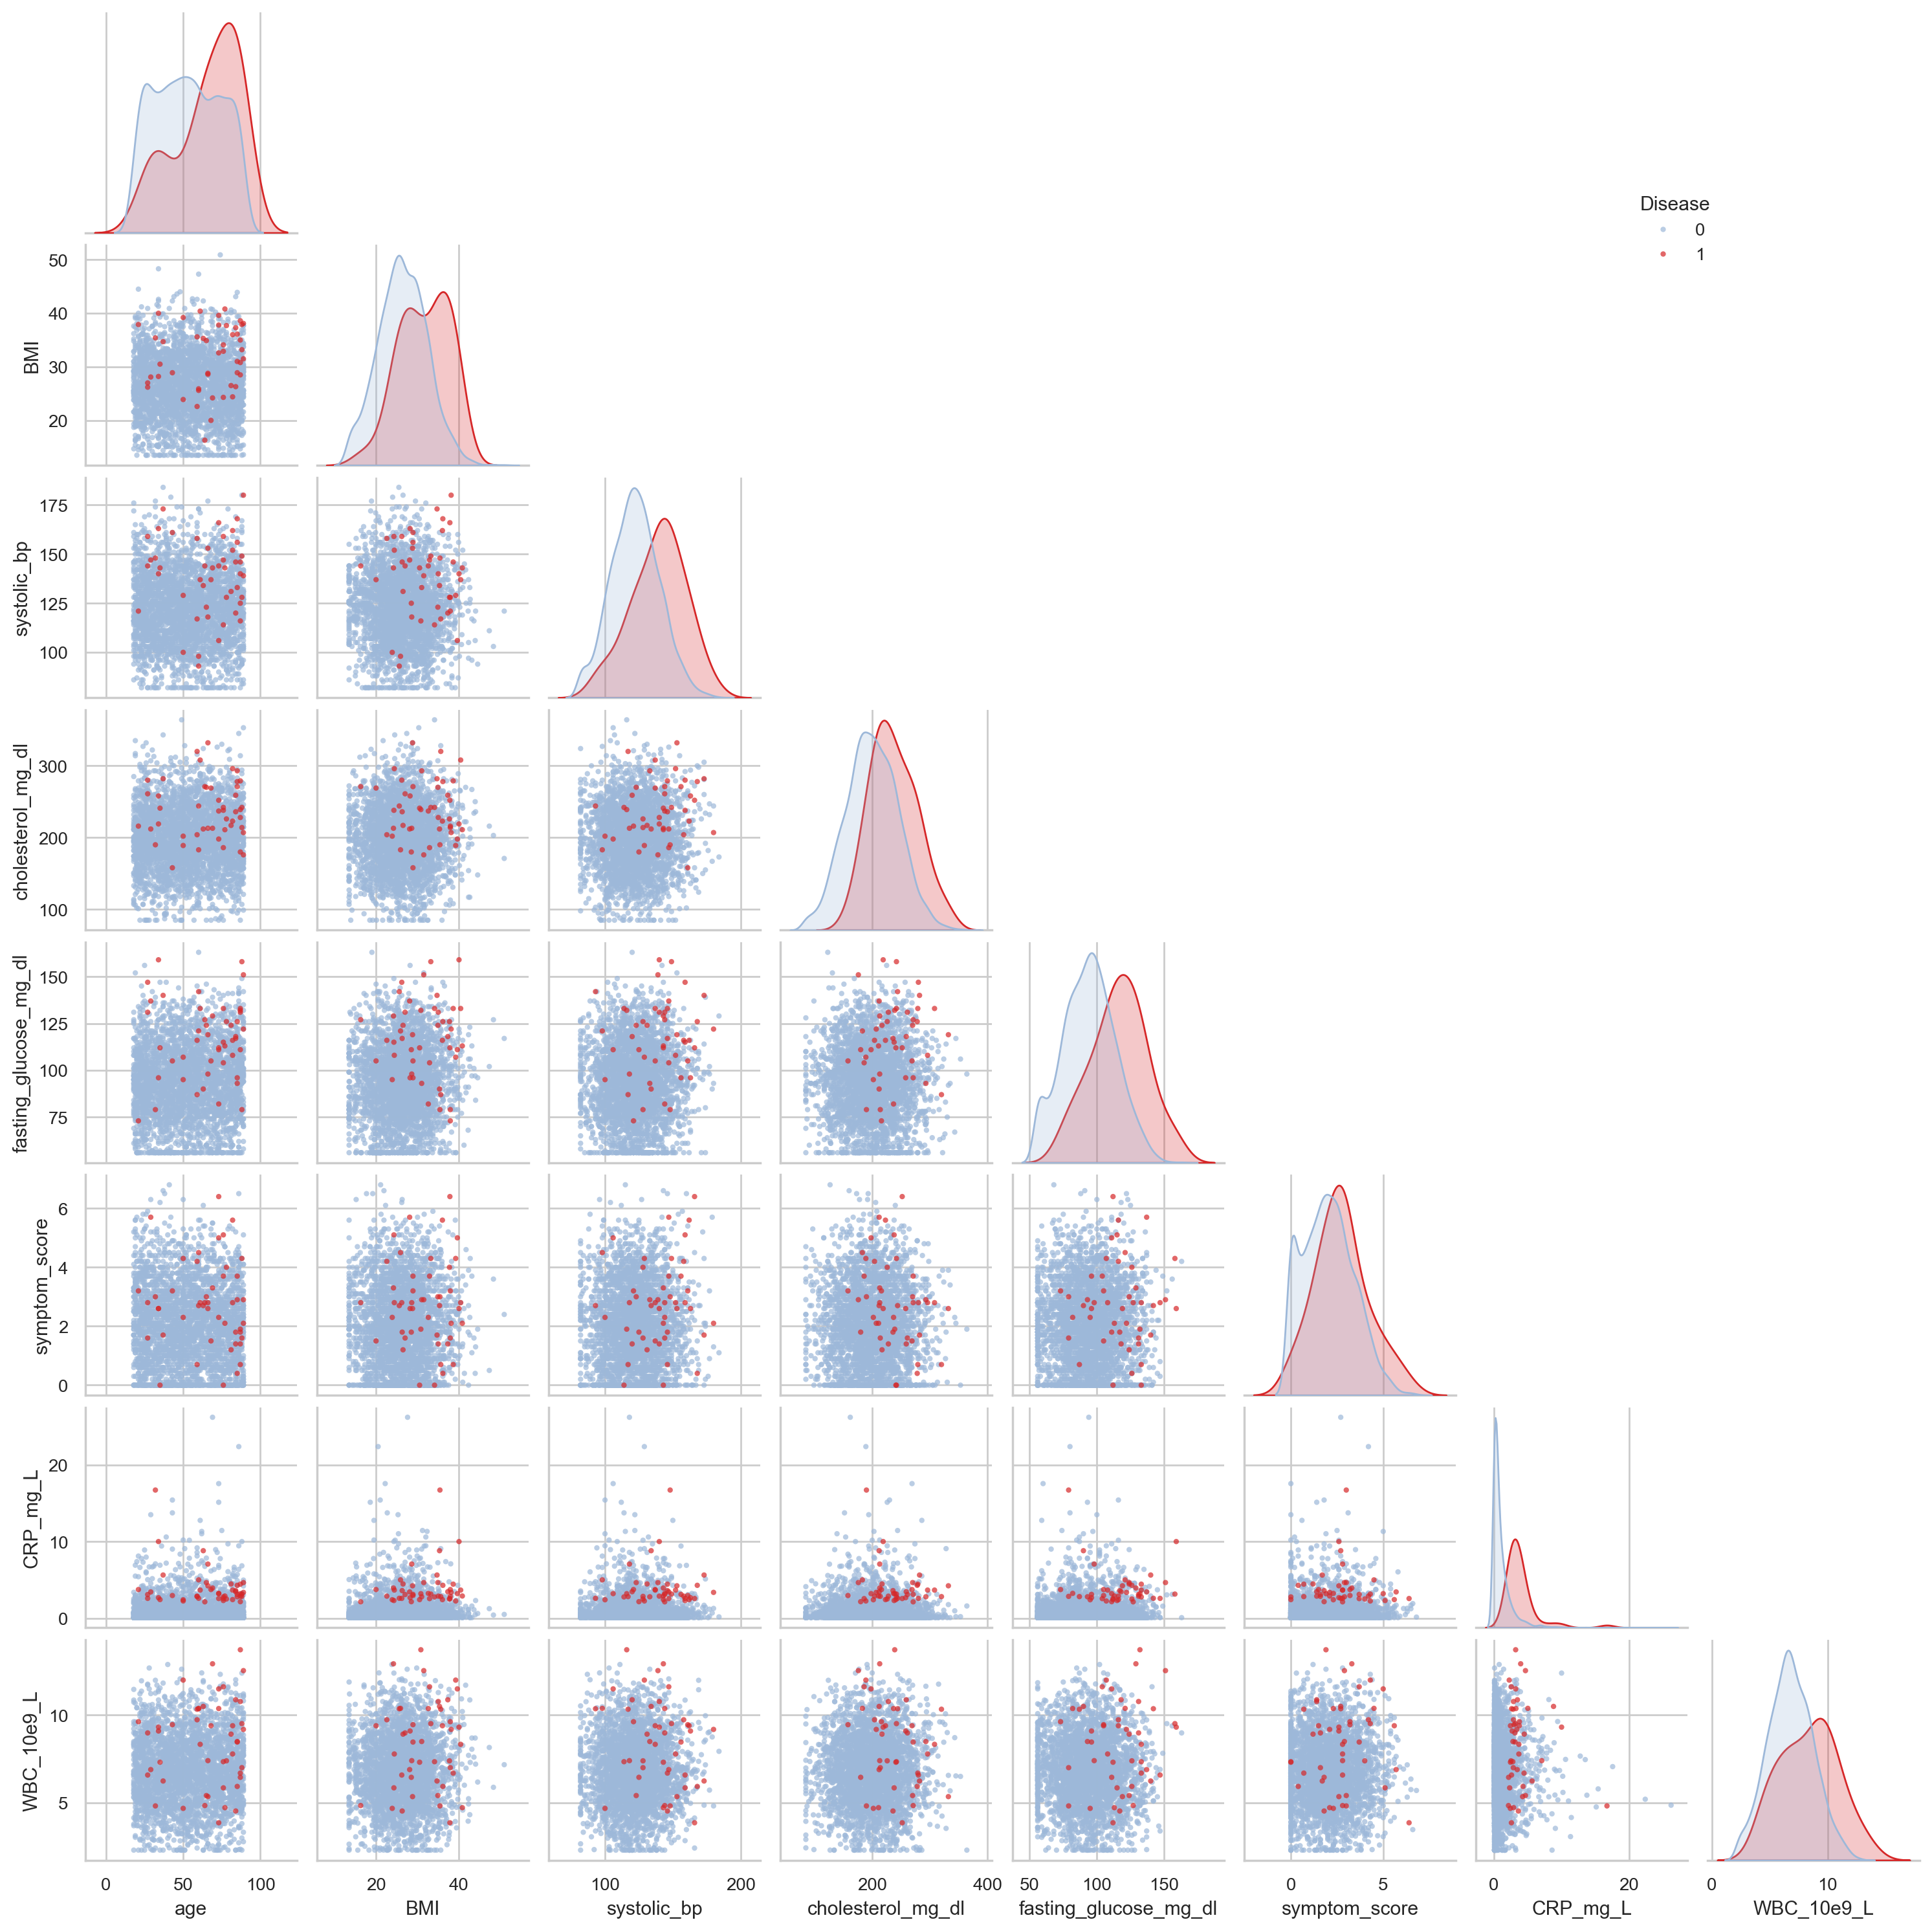

In [24]:
# Больные отсортированы в конец таблицы, чтобы их точки рисовались поверх остальных
with sns.plotting_context('notebook', font_scale=0.9):
    grid = sns.pairplot(medical.sort_values(TARGET), vars=NUMERIC, hue=TARGET, corner=True,
                        height=1.9, palette={0: '#9db8d9', 1: '#d62728'},
                        plot_kws={'s': 9, 'alpha': 0.7, 'linewidth': 0},
                        diag_kws={'common_norm': False})
    sns.move_legend(grid, 'upper right', bbox_to_anchor=(0.85, 0.9))
plt.show()

- Ни на одной диаграмме нет отдельных сгустков точек: пациенты образуют одно сплошное облако. Явных кластеров в данных не видно.
- Облака не вытянуты ни в каком направлении: признаки между собой не связаны.
- Красные точки не образуют отдельной группы, они разбросаны внутри голубого облака. При этом на диагонали кривая распределения больных по каждому признаку сдвинута вправо.
- Заметнее всего отличие по `CRP_mg_L`: красные точки лежат полосой выше основной массы голубых.

Средние значения признаков у здоровых и больных:

In [25]:
min_crp = medical.loc[y == 1, 'CRP_mg_L'].min()
share = (medical['CRP_mg_L'] >= min_crp).mean()
print('Наименьший CRP у больных:', min_crp)
print(f'Доля всех пациентов с таким же или большим CRP: {share:.1%}')

medical.groupby(TARGET)[NUMERIC].mean().round(2).T

Наименьший CRP у больных: 2.16
Доля всех пациентов с таким же или большим CRP: 15.4%


Disease,0,1
age,52.90,65.65
BMI,26.40,31.63
systolic_bp,122.16,139.19
cholesterol_mg_dl,199.22,236.98
fasting_glucose_mg_dl,94.04,116.31
symptom_score,2.03,2.74
CRP_mg_L,1.07,3.90
WBC_10e9_L,6.79,8.39


У больных все восемь признаков в среднем выше: возраст 65.7 года против 52.9, индекс массы тела 31.6 против 26.4, давление 139 против 122, глюкоза 116 против 94, CRP 3.90 против 1.07. Но ни один признак не разделяет классы сам по себе. Даже по CRP: у всех больных он не ниже 2.16, однако такой же или больший CRP у 15.4 % всех пациентов.

### 2.4. Стандартизация

Признаки измеряются в разных единицах: стандартное отклонение холестерина 45.01, а `symptom_score` — 1.36. Без стандартизации расстояние между пациентами почти полностью определялось бы признаками с большим разбросом. Все восемь признаков числовые, и стандартизуются все.

In [26]:
scaler = StandardScaler().set_output(transform='pandas')
X_scaled = scaler.fit_transform(X)

pd.DataFrame({'Среднее до': X.mean(),
              'Ст. отклонение до': X.std(),
              'Среднее после': X_scaled.mean(),
              'Ст. отклонение после': X_scaled.std()}).round(2) + 0

,Среднее до,Ст. отклонение до,Среднее после,Ст. отклонение после
age,53.10,20.73,0.0,1.0
BMI,26.48,5.88,0.0,1.0
systolic_bp,122.44,17.89,0.0,1.0
cholesterol_mg_dl,199.83,45.01,0.0,1.0
fasting_glucose_mg_dl,94.40,19.51,0.0,1.0
symptom_score,2.04,1.36,0.0,1.0
CRP_mg_L,1.12,1.74,0.0,1.0
WBC_10e9_L,6.82,1.98,0.0,1.0


### 2.5. Кластеризация методом k-means

**Подбор числа кластеров.** Для `k` от 1 до 10 считаются сумма квадратов расстояний до центров `J(C_k)` и коэффициент силуэта. Для одного кластера коэффициент силуэта не определён.

In [27]:
selection = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    selection.append({'k': k,
                      'J(C_k)': model.inertia_,
                      'Коэффициент силуэта': (metrics.silhouette_score(X_scaled, model.labels_)
                                              if k > 1 else np.nan),
                      'Размеры кластеров': sorted(np.bincount(model.labels_).tolist(),
                                                  reverse=True)})

selection = pd.DataFrame(selection).set_index('k')
selection.insert(1, 'Снижение, %', -100 * selection['J(C_k)'].pct_change())
selection.round({'J(C_k)': 0, 'Снижение, %': 1, 'Коэффициент силуэта': 3})

,J(C_k),"Снижение, %",Коэффициент силуэта,Размеры кластеров
k,,,,
1,24000.0,NaN,NaN,[3000]
2,21728.0,9.5,0.100,"[1552, 1448]"
3,20143.0,7.3,0.105,"[1452, 1363, 185]"
4,18848.0,6.4,0.096,"[1077, 947, 812, 164]"
5,17805.0,5.5,0.093,"[805, 716, 715, 608, 156]"
6,16969.0,4.7,0.092,"[606, 605, 602, 523, 521, 143]"
7,16244.0,4.3,0.093,"[521, 511, 478, 472, 450, 432, 136]"
8,15578.0,4.1,0.095,"[466, 440, 411, 404, 392, 392, 367, 128]"
9,15136.0,2.8,0.093,"[379, 378, 377, 360, 358, 345, 344, 342, 117]"


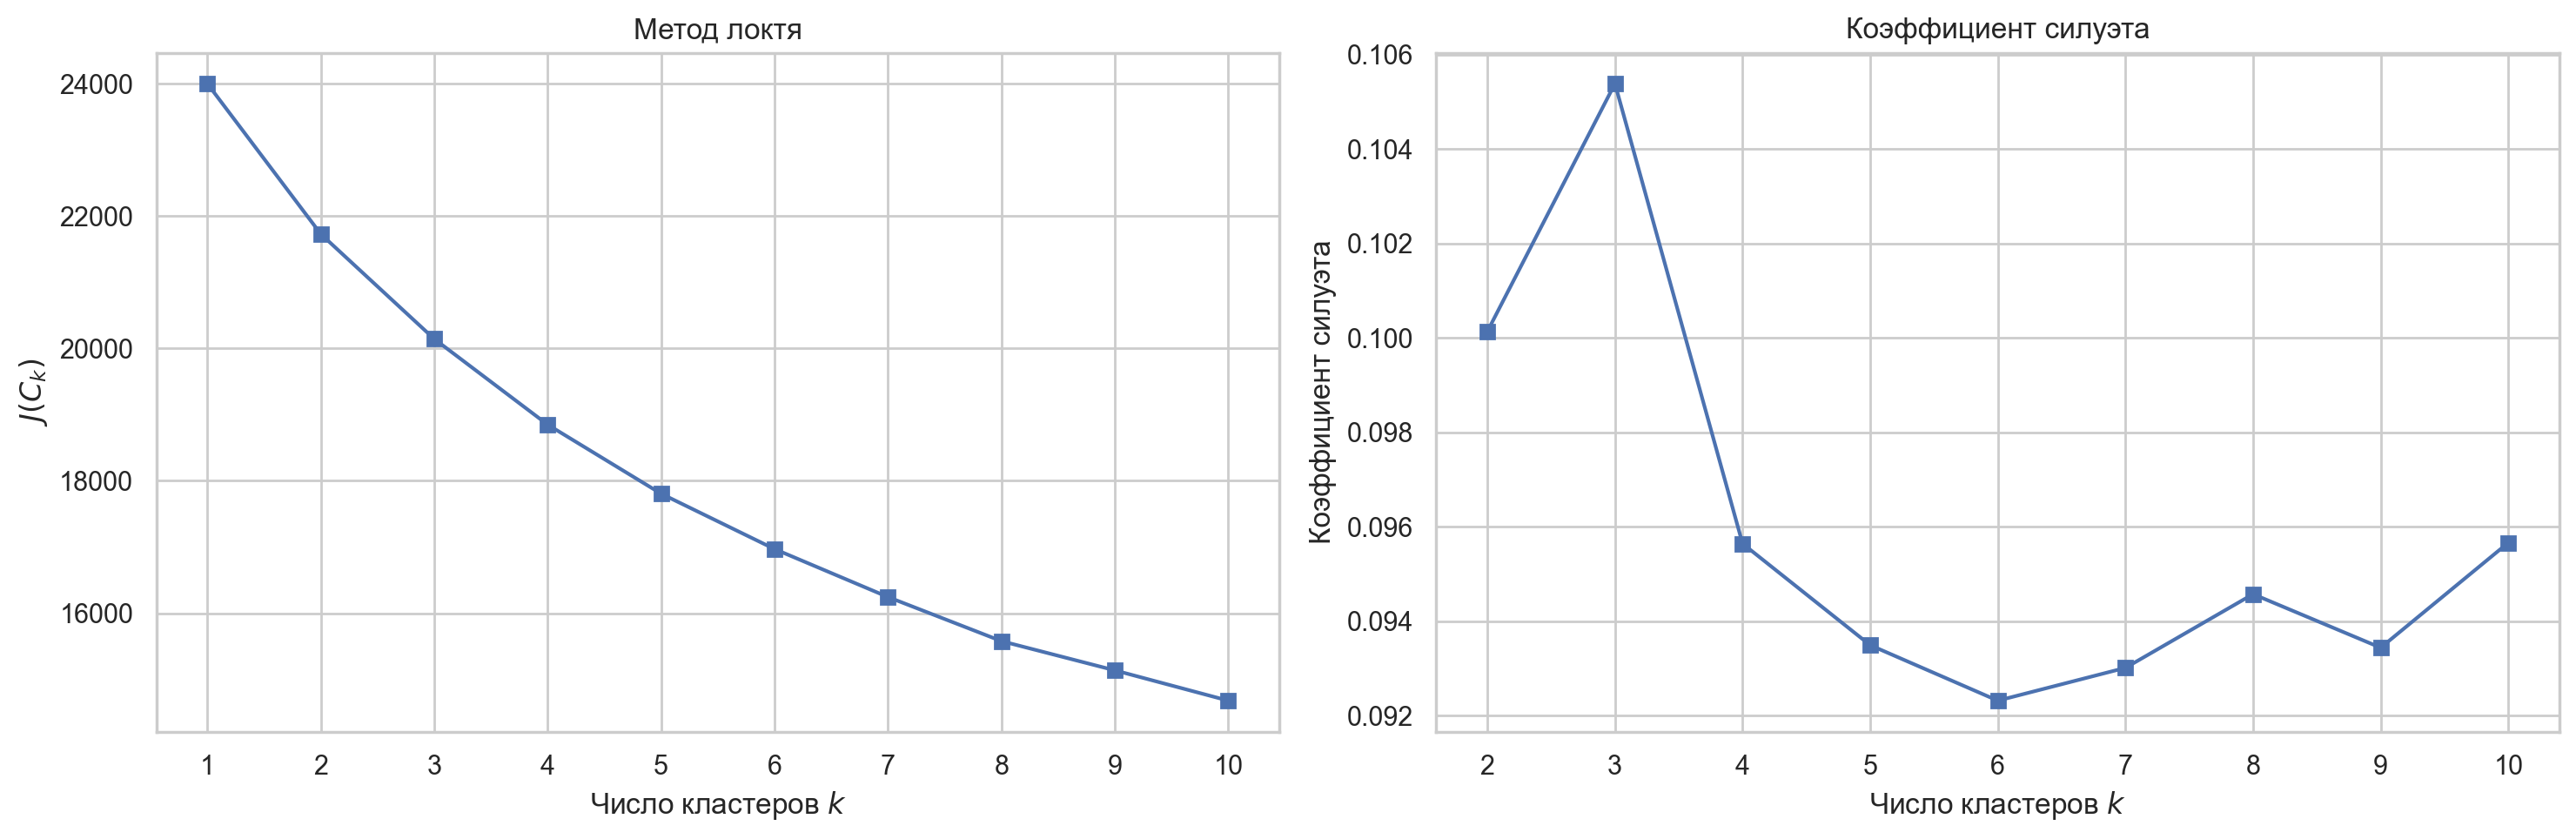

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(selection.index, selection['J(C_k)'], marker='s')
axes[0].set(xlabel='Число кластеров $k$', ylabel='$J(C_k)$', title='Метод локтя',
            xticks=selection.index)

axes[1].plot(selection.index[1:], selection['Коэффициент силуэта'][1:], marker='s')
axes[1].set(xlabel='Число кластеров $k$', ylabel='Коэффициент силуэта',
            title='Коэффициент силуэта', xticks=selection.index[1:])

fig.tight_layout()
plt.show()

- **Метод локтя.** Выраженного локтя нет: `J` убывает плавно, каждый новый кластер снижает её на всё меньшую долю — 9.5 %, 7.3 %, 6.4 %, 5.5 % и так далее. В части 1 переход к трём кластерам снижал `J` на 79 %, здесь самый большой шаг — 9.5 %.
- **Коэффициент силуэта.** Максимум 0.105 достигается при `k = 3`. При `k = 2` он равен 0.100, при остальных `k` — от 0.092 до 0.096.

Оптимальное число кластеров — 3. Но сам коэффициент мал: значение около 0 означает перекрывающиеся кластеры. Это согласуется с матрицей диаграмм рассеяния, где пациенты образуют одно облако.

При `k = 3` кроме двух больших кластеров появляется маленький, из 185 пациентов. Похожий маленький кластер, от 117 до 164 пациентов, сохраняется и при всех больших `k`.

**Итоговая модель** для трёх кластеров. Метки кластеров добавлены в таблицу столбцом `cluster_kmeans`.

In [29]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
medical['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

print('Итераций до сходимости:', kmeans.n_iter_)
medical['cluster_kmeans'].value_counts().sort_index().rename('Пациентов').to_frame()

Итераций до сходимости: 31


,Пациентов
cluster_kmeans,
0,185
1,1452
2,1363


Алгоритм сошёлся за 31 итерацию. Получились два больших кластера, 1452 и 1363 пациента, и один маленький — 185 пациентов.

### 2.6. Анализ кластеров

Средние значения признаков в каждом кластере в исходных единицах. Последний столбец — средние по всем пациентам. Последняя строка, среднее `Disease`, — это доля больных.

In [30]:
def cluster_means(column):
    """Средние значения признаков и доля больных по кластерам и по всему набору."""
    means = medical.groupby(column)[NUMERIC + [TARGET]].mean().T
    means['Все пациенты'] = medical[NUMERIC + [TARGET]].mean()
    return means.round(2)


cluster_means('cluster_kmeans')

cluster_kmeans,0,1,2,Все пациенты
age,56.90,35.73,71.09,53.10
BMI,26.17,27.14,25.82,26.48
systolic_bp,122.97,122.86,121.91,122.44
cholesterol_mg_dl,198.47,196.87,203.15,199.83
fasting_glucose_mg_dl,98.30,92.65,95.73,94.40
symptom_score,2.00,2.15,1.93,2.04
CRP_mg_L,6.20,0.79,0.78,1.12
WBC_10e9_L,6.91,6.67,6.96,6.82
Disease,0.08,0.01,0.02,0.02


Те же центры в стандартизованных признаках (атрибут `cluster_centers_`). Они показывают, на сколько стандартных отклонений кластер отличается от среднего пациента:

In [31]:
std_centers = pd.DataFrame(kmeans.cluster_centers_, columns=NUMERIC)
std_centers.rename_axis('cluster_kmeans').round(2).T

cluster_kmeans,0,1,2
age,0.18,-0.83,0.87
BMI,-0.05,0.11,-0.11
systolic_bp,0.03,0.02,-0.03
cholesterol_mg_dl,-0.03,-0.07,0.08
fasting_glucose_mg_dl,0.20,-0.09,0.06
symptom_score,-0.03,0.08,-0.08
CRP_mg_L,2.93,-0.19,-0.19
WBC_10e9_L,0.04,-0.08,0.08


Кластеры различаются по двум признакам. По возрасту центры кластеров 1 и 2 отстоят от среднего на −0.83 и +0.87 стандартного отклонения, по CRP центр кластера 0 — на +2.93. По остальным шести признакам отклонения не больше 0.20.

Границы кластеров по этим двум признакам и диаграмма рассеяния в осях возраст — CRP:

In [32]:
medical.groupby('cluster_kmeans')[['age', 'CRP_mg_L']].agg(['min', 'median', 'max'])

age            CRP_mg_L              
               min median max      min median    max
cluster_kmeans                                      
0               19   59.0  89     3.51   5.09  26.20
1               18   35.5  65     0.10   0.44   4.00
2               43   72.0  89     0.10   0.44   3.74

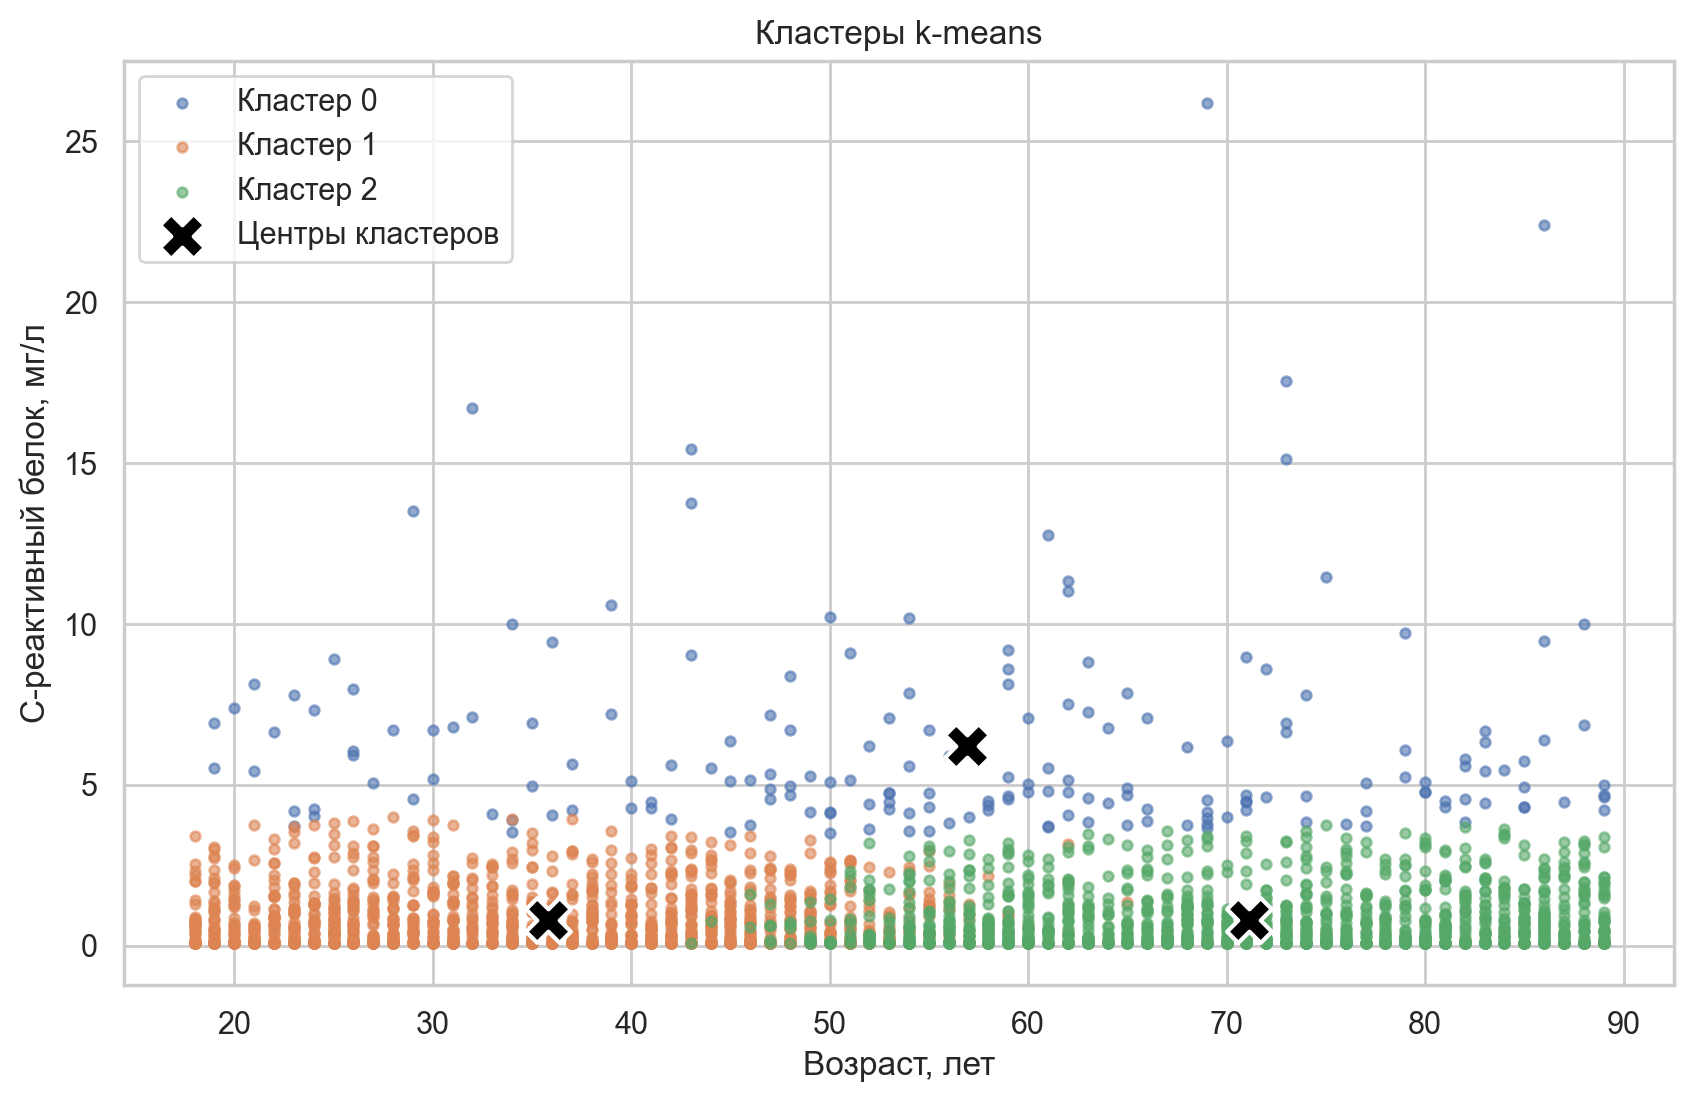

In [33]:
def plot_age_crp(ax, column, title):
    """Пациенты в осях возраст — C-реактивный белок, окрашенные по кластерам."""
    for cluster, members in medical.groupby(column):
        ax.scatter(members['age'], members['CRP_mg_L'], s=12, alpha=0.6,
                   label=f'Кластер {cluster}')
    ax.set(xlabel='Возраст, лет', ylabel='C-реактивный белок, мг/л', title=title)


fig, ax = plt.subplots(figsize=(10, 6))
plot_age_crp(ax, 'cluster_kmeans', 'Кластеры k-means')
centers = pd.DataFrame(scaler.inverse_transform(std_centers), columns=NUMERIC)
ax.scatter(centers['age'], centers['CRP_mg_L'], marker='X', s=260, color='black',
           edgecolor='white', linewidth=1.5, label='Центры кластеров')
ax.legend()
plt.show()

- **Кластер 0 — пациенты с повышенным C-реактивным белком,** 185 человек (6.2 %). CRP у всех не ниже 3.51, в среднем 6.20 — в 5.5 раза выше среднего по набору. Возраст любой, от 19 до 89 лет. Глюкоза немного выше средней: 98.3 против 94.4. Доля больных 8 % при 2 % по всему набору.
- **Кластер 1 — молодые пациенты,** 1452 человека (48.4 %). Средний возраст 35.7 года, самому старшему 65 лет. CRP низкий: в среднем 0.79, не выше 4.00. Доля больных наименьшая, 1 %.
- **Кластер 2 — пожилые пациенты,** 1363 человека (45.4 %). Средний возраст 71.1 года, самому младшему 43 года. CRP такой же низкий: в среднем 0.78. Доля больных 2 %, как по всему набору.

На диаграмме видно, как устроено разбиение. Кластер 0 отделён от остальных по уровню CRP, граница проходит около 3.5–4 мг/л. Кластеры 1 и 2 разделены по возрасту, граница проходит около 53 лет. Пустого пространства между кластерами нет: границы проведены внутри сплошного облака точек. По давлению, холестерину, индексу массы тела и лейкоцитам кластеры не различаются.

### 2.7. Метрики качества

**Коэффициент силуэта** — внутренняя метрика: для неё нужны только признаки и метки кластеров.

Внешние метрики сравнивают кластеры с известными классами `Disease`:

- **ARI** — доля пар объектов, по которым два разбиения согласны, с поправкой на случайное совпадение. 1 — разбиения совпадают, около 0 — согласие случайное.
- **AMI** — взаимная информация двух разбиений с такой же поправкой.
- **FMI** — индекс Фаулкса — Мэллоуса: среднее геометрическое точности и полноты, посчитанных по парам объектов. От 0 до 1.
- **Homogeneity** — однородность: 1, если каждый кластер состоит из объектов одного класса.
- **Completeness** — полнота: 1, если все объекты одного класса попали в один кластер.
- **V-measure** — гармоническое среднее однородности и полноты.

In [34]:
def clustering_metrics(labels):
    """Коэффициент силуэта и внешние метрики — сравнение кластеров с классами Disease."""
    return {'Силуэт': metrics.silhouette_score(X_scaled, labels),
            'ARI': metrics.adjusted_rand_score(y, labels),
            'AMI': metrics.adjusted_mutual_info_score(y, labels),
            'FMI': metrics.fowlkes_mallows_score(y, labels),
            'Homogeneity': metrics.homogeneity_score(y, labels),
            'Completeness': metrics.completeness_score(y, labels),
            'V-measure': metrics.v_measure_score(y, labels)}


results = {'k-means': clustering_metrics(medical['cluster_kmeans'])}
pd.DataFrame(results).T.round(3)

,Силуэт,ARI,AMI,FMI,Homogeneity,Completeness,V-measure
k-means,0.105,0.012,0.012,0.661,0.076,0.007,0.013


In [35]:
def disease_by_cluster(column):
    """Число здоровых и больных в каждом кластере и доля больных."""
    table = pd.crosstab(medical[column], medical[TARGET])
    share = 100 * table[1] / table.sum(axis=1)
    table['Доля больных, %'] = share.round(1)
    return table


disease_by_cluster('cluster_kmeans')

Disease,0,1,"Доля больных, %"
cluster_kmeans,,,
0,170,15,8.1
1,1443,9,0.6
2,1339,24,1.8


- Коэффициент силуэта 0.105: кластеры перекрываются.
- ARI = 0.012 и AMI = 0.012: совпадение кластеров с классами `Disease` почти не отличается от случайного.
- Homogeneity = 0.076, Completeness = 0.007, V-measure = 0.013. В каждом кластере преобладают здоровые, а больные распределены по всем трём кластерам: 15, 9 и 24 человека.
- FMI = 0.661 выглядит высоким, но это следствие дисбаланса классов. Здоровых 98.4 %, поэтому почти любая пара пациентов принадлежит одному классу, и большое значение получается при любом разбиении на несколько крупных кластеров.

Кластеры не воспроизводят деление на больных и здоровых. Алгоритм уменьшает разброс внутри кластеров, а больные составляют 1.6 % набора и на суммарный разброс почти не влияют. При этом кластер 0 содержателен: доля больных в нём 8.1 % — в пять раз выше, чем по всему набору (1.6 %).

### 2.8. Иерархическая агломеративная кластеризация

Агломеративный алгоритм начинает с того, что каждый объект — отдельный кластер, и на каждом шаге объединяет два ближайших кластера, пока не останется один. Использован метод Уорда: объединяются те два кластера, слияние которых меньше всего увеличивает внутрикластерную дисперсию. Он уменьшает ту же величину, что и k-means, поэтому результаты двух методов сравнимы. Расстояние между объектами евклидово.

Функция `linkage` возвращает историю объединений: в каждой строке — номера двух объединяемых кластеров, расстояние между ними и размер нового кластера. По ней функция `dendrogram` строит дерево.

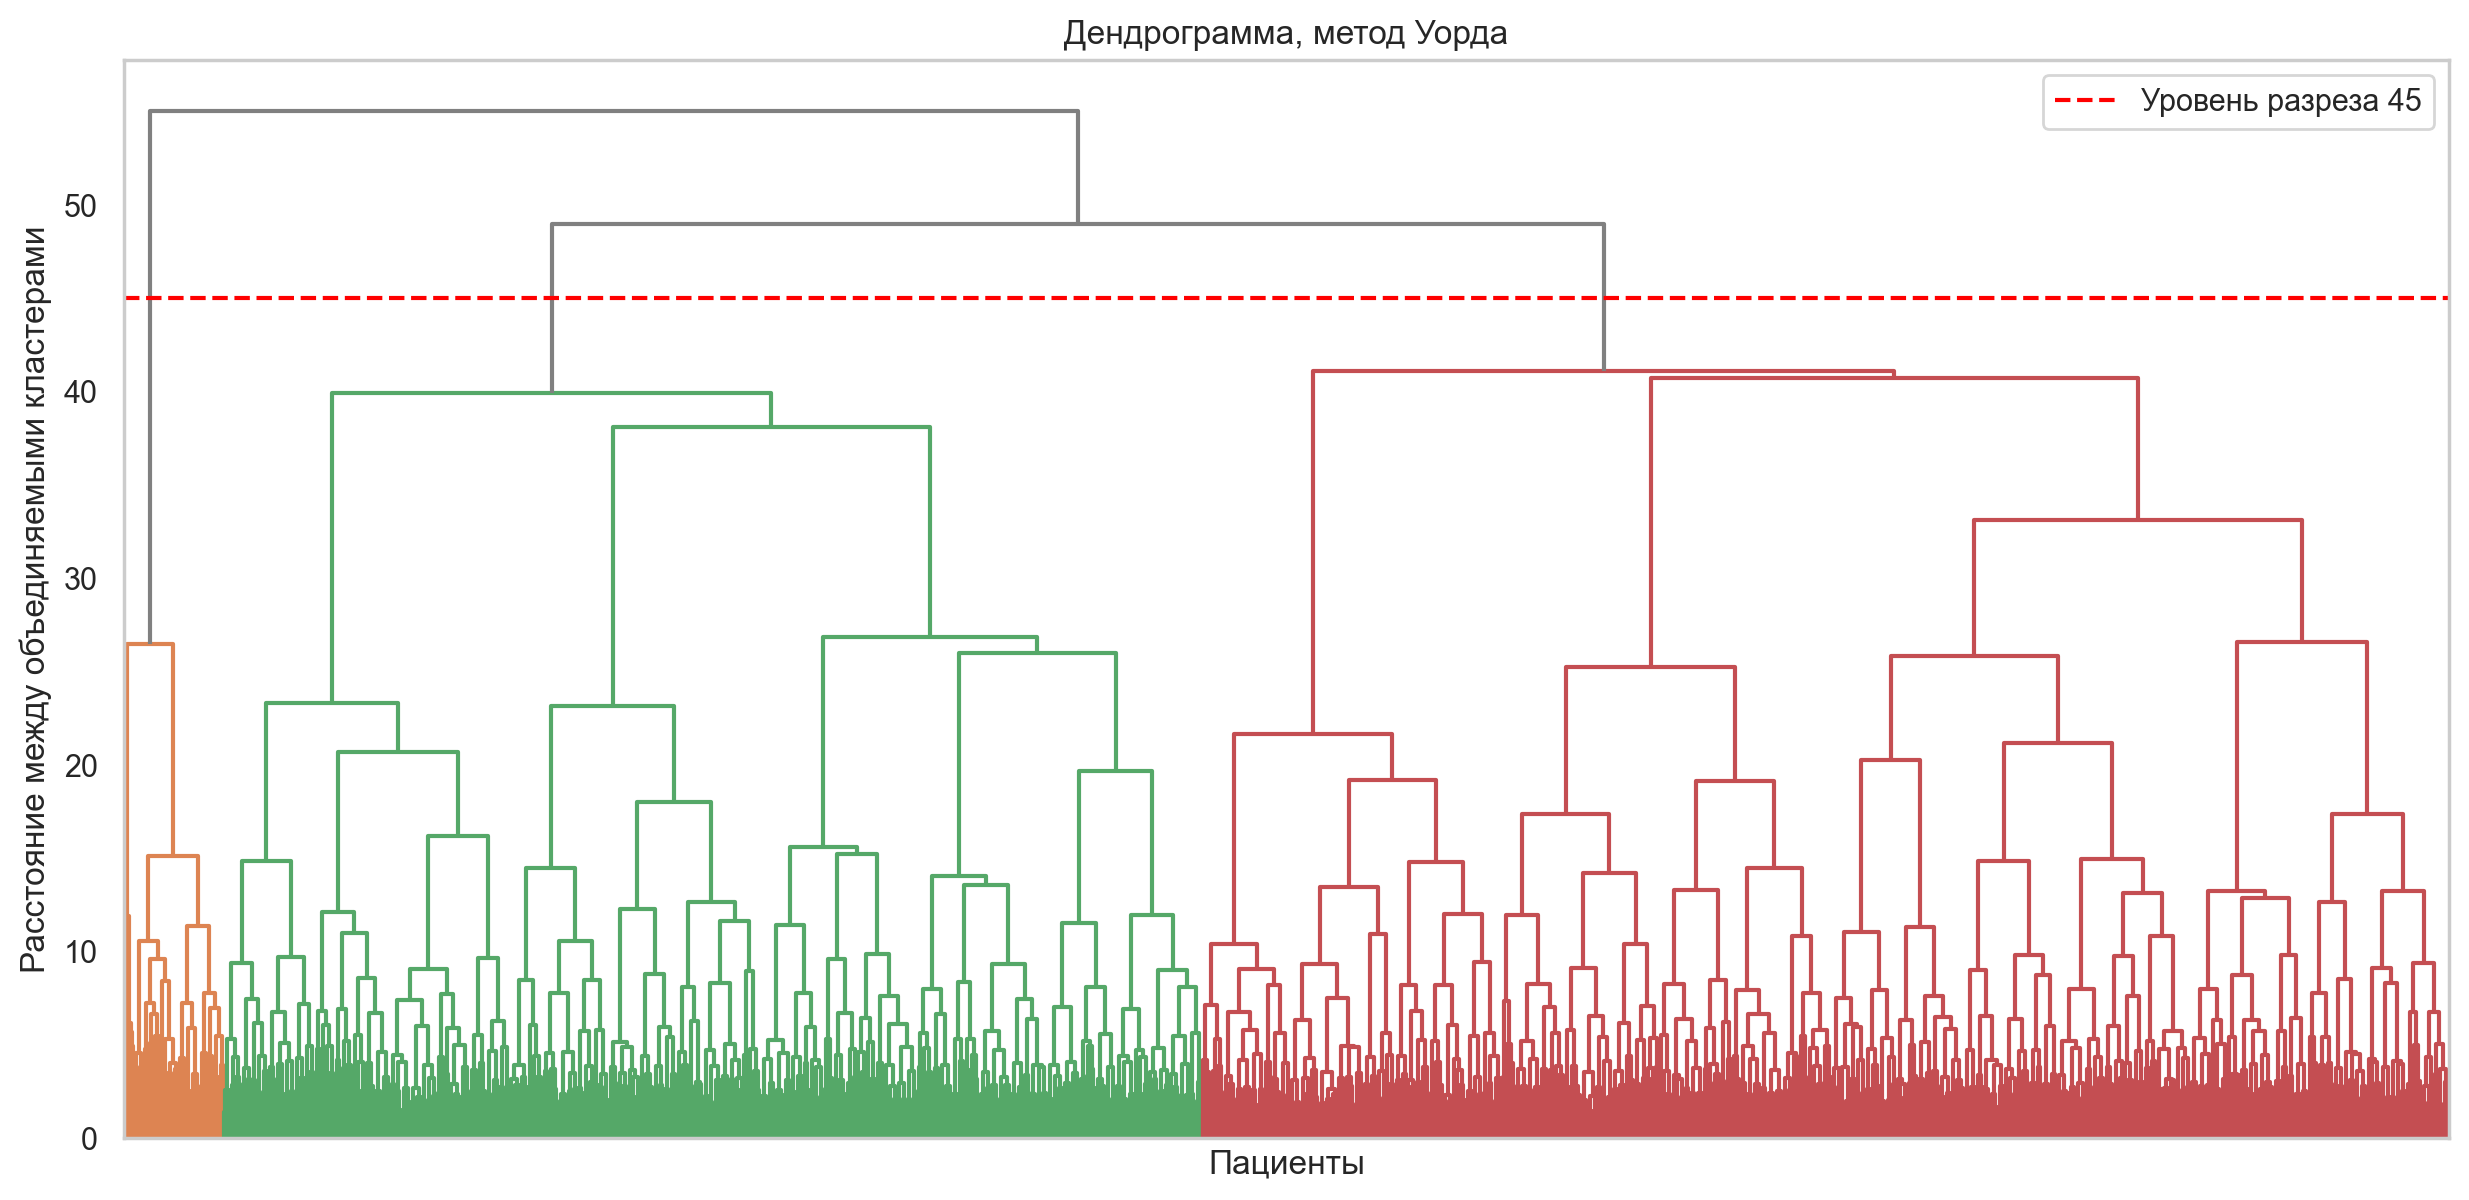

In [36]:
linked = linkage(X_scaled, method='ward')

CUT_DISTANCE = 45

fig, ax = plt.subplots(figsize=(15, 7))
dendrogram(linked, orientation='top', no_labels=True, color_threshold=CUT_DISTANCE,
           above_threshold_color='gray', ax=ax)
ax.axhline(CUT_DISTANCE, color='red', linestyle='--', label=f'Уровень разреза {CUT_DISTANCE}')
ax.grid(False)
ax.set(xlabel='Пациенты', ylabel='Расстояние между объединяемыми кластерами',
       title='Дендрограмма, метод Уорда')
ax.legend()
plt.show()

По горизонтали — 3000 пациентов, по вертикали — расстояние, на котором кластеры объединились. Чем длиннее вертикальные ветви между двумя соседними объединениями, тем сильнее различаются кластеры, которые они разделяют. Расстояния последних десяти объединений:

In [37]:
last_merges = pd.DataFrame({'Кластеров до объединения': range(11, 1, -1),
                            'Кластеров после объединения': range(10, 0, -1),
                            'Расстояние': linked[-10:, 2]})
last_merges['Скачок расстояния'] = last_merges['Расстояние'].diff()
last_merges.round(2)

,Кластеров до объединения,Кластеров после объединения,Расстояние,Скачок расстояния
0,11,10,26.44,NaN
1,10,9,26.57,0.13
2,9,8,26.83,0.26
3,8,7,33.11,6.29
4,7,6,38.08,4.96
5,6,5,39.90,1.82
6,5,4,40.71,0.81
7,4,3,41.06,0.35
8,3,2,48.95,7.89
9,2,1,54.99,6.04


Самый большой скачок расстояния — 7.89. Четыре кластера объединяются в три на расстоянии 41.06, а три в два — только на расстоянии 48.95. Между этими уровнями дерево можно разрезать, не задев ни одного объединения: красная пунктирная линия на уровне 45 пересекает три вертикальные ветви. Оптимальное число кластеров по дендрограмме — 3. Следующие по величине скачки, 6.29 и 6.04, соответствуют восьми и двум кластерам.

Коэффициент силуэта для разрезов дерева на 2–6 кластеров:

In [38]:
ward_selection = []
for k in range(2, 7):
    labels = fcluster(linked, t=k, criterion='maxclust')
    ward_selection.append({'k': k,
                           'Коэффициент силуэта': metrics.silhouette_score(X_scaled, labels),
                           'Размеры кластеров': sorted(np.bincount(labels)[1:].tolist(),
                                                       reverse=True)})

pd.DataFrame(ward_selection).set_index('k').round(3)

,Коэффициент силуэта,Размеры кластеров
k,,
2,0.270,"[2871, 129]"
3,0.060,"[1609, 1262, 129]"
4,0.034,"[1262, 1222, 387, 129]"
5,0.032,"[1262, 796, 426, 387, 129]"
6,0.035,"[895, 796, 426, 387, 367, 129]"


По коэффициенту силуэта лучше два кластера: 0.270. Но такое разбиение почти ничего не сообщает о пациентах: от 2871 человека отделены 129 с самым высоким CRP. Коэффициент высок, потому что для 96 % объектов единственный чужой кластер — эта далёкая маленькая группа. При трёх кластерах большой кластер делится на два, и коэффициент падает до 0.060.

Выбраны 3 кластера: на них указывает наибольший скачок на дендрограмме, и результат можно напрямую сравнить с k-means. Модель `AgglomerativeClustering` с методом Уорда даёт то же разбиение, что и разрез дерева на три кластера. Метки добавлены в таблицу столбцом `cluster_agglo`.

In [39]:
agglomerative = AgglomerativeClustering(n_clusters=3, linkage='ward')
medical['cluster_agglo'] = agglomerative.fit_predict(X_scaled)

medical['cluster_agglo'].value_counts().sort_index().rename('Пациентов').to_frame()

,Пациентов
cluster_agglo,
0,1609
1,129
2,1262


In [40]:
cluster_means('cluster_agglo')

cluster_agglo,0,1,2,Все пациенты
age,43.61,59.97,64.51,53.10
BMI,26.68,25.98,26.27,26.48
systolic_bp,121.06,124.33,123.99,122.44
cholesterol_mg_dl,197.83,196.05,202.76,199.83
fasting_glucose_mg_dl,88.22,99.78,101.73,94.40
symptom_score,2.27,1.84,1.76,2.04
CRP_mg_L,0.90,6.87,0.81,1.12
WBC_10e9_L,6.73,6.79,6.93,6.82
Disease,0.00,0.05,0.03,0.02


In [41]:
medical.groupby('cluster_agglo')[['age', 'CRP_mg_L']].agg(['min', 'median', 'max'])

age            CRP_mg_L              
              min median max      min median    max
cluster_agglo                                      
0              18   40.0  89     0.10   0.50   7.20
1              19   62.0  89     2.28   6.06  26.20
2              18   67.0  89     0.10   0.43   5.65

Номера кластеров у двух методов не связаны между собой.

- **Кластер 1 — пациенты с повышенным C-реактивным белком,** 129 человек (4.3 %). Средний CRP 6.87, наименьший 2.28. Это аналог кластера 0 у k-means, но меньше.
- **Кластер 0,** 1609 человек (53.6 %). Пациенты моложе среднего (43.6 года), глюкоза ниже средней (88.2 против 94.4), выраженность симптомов выше (2.27 против 2.04).
- **Кластер 2,** 1262 человека (42.1 %). Пациенты старше среднего (64.5 года), глюкоза выше средней (101.7), выраженность симптомов ниже (1.76).

В отличие от k-means, кластеры 0 и 2 не разделены по возрасту: в обоих есть пациенты от 18 до 89 лет. Они различаются сразу по трём признакам — возрасту, глюкозе и выраженности симптомов, — но по каждому слабо.

Метрики качества рядом с метриками k-means:

In [42]:
results['Агломеративная кластеризация'] = clustering_metrics(medical['cluster_agglo'])
pd.DataFrame(results).T.round(3)

,Силуэт,ARI,AMI,FMI,Homogeneity,Completeness,V-measure
k-means,0.105,0.012,0.012,0.661,0.076,0.007,0.013
Агломеративная кластеризация,0.060,0.009,0.011,0.676,0.068,0.007,0.012


In [43]:
disease_by_cluster('cluster_agglo')

Disease,0,1,"Доля больных, %"
cluster_agglo,,,
0,1602,7,0.4
1,123,6,4.7
2,1227,35,2.8


- Коэффициент силуэта 0.060 — почти вдвое ниже, чем у k-means (0.105).
- Внешние метрики такие же низкие: ARI = 0.009, AMI = 0.011, V-measure = 0.012. Деление на больных и здоровых этот метод тоже не воспроизводит.
- В кластере с повышенным CRP доля больных 4.7 % (6 из 129). У k-means в таком же кластере 8.1 % (15 из 185).

### 2.9. Сравнение методов

Насколько совпадают два разбиения:

In [44]:
partition_ari = metrics.adjusted_rand_score(medical['cluster_kmeans'],
                                            medical['cluster_agglo'])
print(f'ARI между разбиениями двух методов: {partition_ari:.3f}')

pd.crosstab(medical['cluster_kmeans'], medical['cluster_agglo'])

ARI между разбиениями двух методов: 0.271


cluster_agglo,0,1,2
cluster_kmeans,,,
0,42,118,25
1,1148,0,304
2,419,11,933


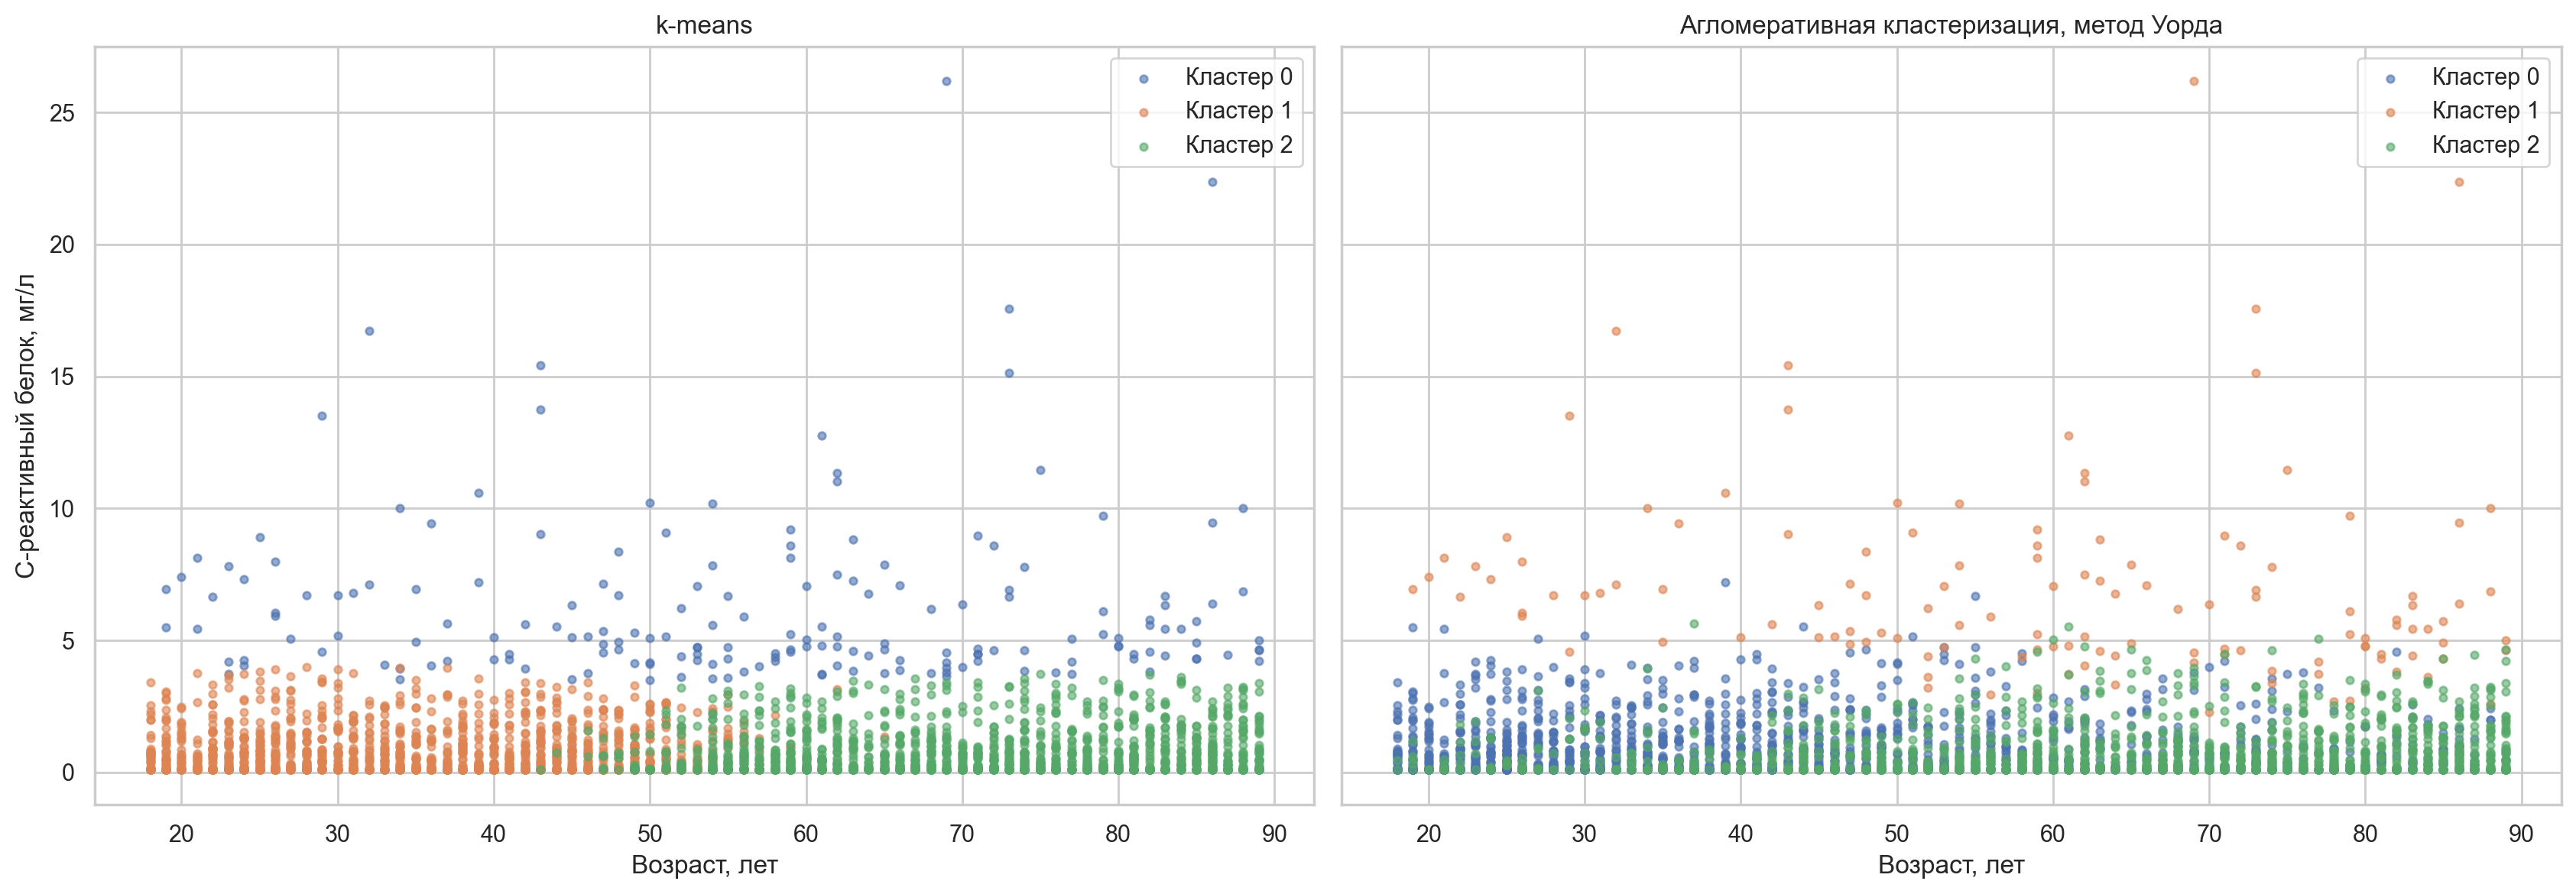

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

plot_age_crp(axes[0], 'cluster_kmeans', 'k-means')
plot_age_crp(axes[1], 'cluster_agglo', 'Агломеративная кластеризация, метод Уорда')
for ax in axes:
    ax.legend()
axes[1].set_ylabel('')

fig.tight_layout()
plt.show()

ARI между разбиениями равен 0.271: методы согласны лишь отчасти.

- Группу с повышенным CRP находят оба метода: из 129 пациентов кластера 1 по методу Уорда 118 входят в кластер 0 у k-means.
- Два больших кластера проведены по-разному. Из «молодого» кластера k-means 304 пациента попали в старший кластер Уорда, из «пожилого» 419 — в младший. На левой диаграмме граница по возрасту чёткая, на правой синие и зелёные точки перемешаны.

Причина расхождения — в самих данных: явных кластеров в них нет, и границу внутри сплошного облака каждый алгоритм проводит по-своему.

| | k-means | Агломеративная кластеризация |
|---|---|---|
| Число кластеров | 3 | 3 |
| Размеры кластеров | 1452, 1363, 185 | 1609, 1262, 129 |
| Коэффициент силуэта | 0.105 | 0.060 |
| ARI с классами `Disease` | 0.012 | 0.009 |
| Доля больных в кластере с повышенным CRP | 8.1 % | 4.7 % |

**Целесообразнее использовать k-means:**

- коэффициент силуэта у него почти вдвое выше;
- кластеры проще описать: молодые пациенты, пожилые пациенты и пациенты с повышенным CRP. Кластеры метода Уорда различаются по нескольким признакам сразу и по каждому слабо;
- k-means на каждой итерации заново распределяет объекты по кластерам, а агломеративный алгоритм объединение, сделанное на раннем шаге, уже не пересматривает;
- k-means лучше подходит для больших выборок: агломеративному алгоритму нужны попарные расстояния между всеми объектами, а их число растёт как квадрат размера выборки.

Иерархический метод полезен на другом этапе: дендрограмма показывает структуру данных и помогает выбрать число кластеров, не задавая его заранее. Здесь она подтвердила выбор трёх кластеров.

## Выводы по работе

В работе изучены два метода кластеризации — k-means и иерархическая агломеративная кластеризация — и метрики качества кластеризации.

- **Часть 1.** На 300 сгенерированных объектах трёх групп k-means после стандартизации точно восстановил группы. Коэффициент силуэта максимален при трёх кластерах (0.720 против 0.499 для двух и 0.585 для четырёх), метод локтя указывает на то же число.
- **Часть 2, данные.** Набор `medical_diagnosis.csv` — 3031 запись о пациентах: 8 числовых и 5 категориальных признаков и целевой класс `Disease`. Пропусков нет. Удалена 31 аномальная строка с одновременно завышенными холестерином и CRP, среди них был единственный дубликат; осталось 3000 строк. Больных 48, то есть 1.6 %. Для кластеризации взяты 8 числовых признаков, они стандартизованы.
- **Часть 2, k-means.** Выраженного локтя нет, коэффициент силуэта максимален при трёх кластерах и равен 0.105. Кластеры: молодые пациенты (1452 человека, средний возраст 35.7 года), пожилые (1363 человека, 71.1 года) и пациенты с повышенным CRP (185 человек, CRP в среднем 6.20 при 1.12 по набору). В последнем кластере доля больных 8.1 % — в пять раз выше средней.
- **Часть 2, агломеративная кластеризация.** Наибольший скачок на дендрограмме соответствует трём кластерам. Их размеры 1609, 1262 и 129 пациентов, коэффициент силуэта 0.060.
- **Сравнение с классами.** Внешние метрики у обоих методов около нуля (ARI 0.012 и 0.009): кластеры не совпадают с делением на больных и здоровых.

Целесообразнее использовать k-means: у него выше коэффициент силуэта, кластеры проще интерпретировать, и он лучше подходит для больших выборок.

Общий вывод: качество кластеризации определяется прежде всего самими данными. Когда группы отделены друг от друга, как в части 1, k-means находит их безошибочно, и все способы выбора числа кластеров дают один ответ. В данных о пациентах отделённых групп нет: коэффициент силуэта около 0.1, а кластеры — это условные сегменты, границы которых проведены внутри сплошного облака. Диагноз такая кластеризация не восстанавливает, но выделяет группу риска — пациентов с повышенным C-реактивным белком.